In [151]:
import numpy as np
import FBA_ode

Final H2O2_cyt: 7.392542417802025e-06
Final Ca_cyt  : 9.314087451455111e-08
Pmax H2O2 (s^-1): 0.3319160934010085   Pmax Ca (s^-1): 0.13829837225042024


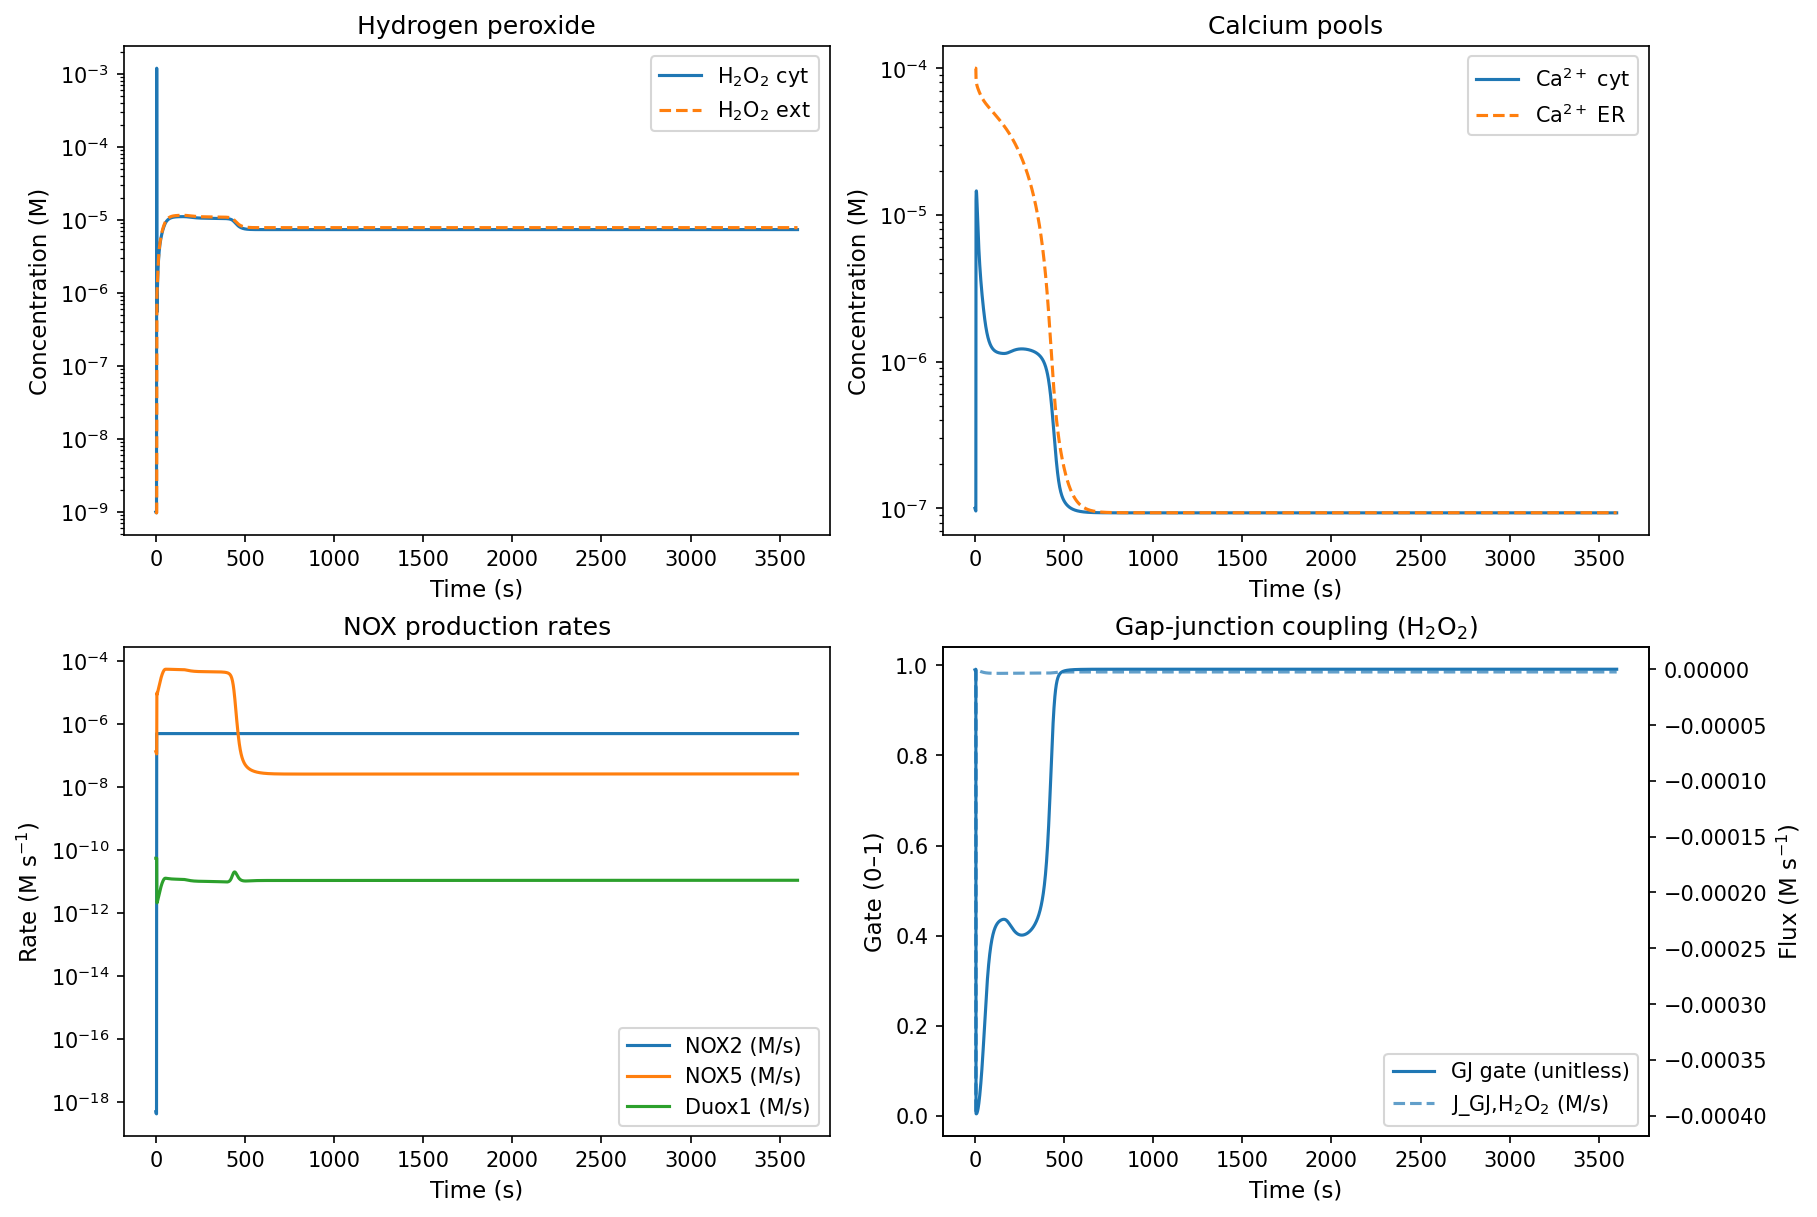

In [152]:
import numpy as np
from scipy.integrate import solve_ivp

# -----------------------------
# Gap junction physics helper
# -----------------------------
def gj_Pmax(N_open, D_cm2_s, r_cm, L_cm, Vcyt_cm3):
    """
    Max first-order coupling rate through N_open identical pores:
      P_max = (D * N_open * π r^2) / (L * V_cyt)       [s^-1]
    """
    return (D_cm2_s * N_open * np.pi * r_cm**2) / (L_cm * Vcyt_cm3)


# -----------------------------
# Parameters (k) and initials (x0)
# -----------------------------
def get_k():
    k = np.zeros(100)
# --- your original core parameters (kept as you used them) ---
    k[0] = 2e-2  # Permeability constant (plasma membrane) (cm/s)
    k[1] = 14.75e-7  # Intracellular peroxide production (M/s)
    k[2] = 2.1e7  # GPx_red reacting with H2O2in (M-1*s-1)
    k[3] = 4e4  # GPx_ox reacting with GSH (M-1*s-1)
    k[4] = 1e7  # GPx-SSG reacting with GSH (M-1*s-1)
    k[5] = 3.4e7  # Catalase reacts with H2O2 inside peroxisome (M-1*s-1)
    k[6] = 5.7e-5  # Km of NADP+ (M)
    k[7] = 100e-6  # Peroxiredoxin is oxidized by H2O2 (M-1*s-1)
    k[8] = 0.0049e-6  # Oxidized peroxiredoxin is over-oxidized by H2O2 (M-1*s-1)
    k[9] = 3e-3  # Reduction of overoxidized Prx by Srx enzyme (s-1)
    k[10] = 15  # Self-catalyzed disulfide formation of Prx-SS from Prx-SOH (s-1)
    k[11] = 2.1e-6 # Peroxiredoxin is reduced by Thioredoxin (M-1*s-1)
    k[12] = 7.4e-05  # Auto-oxidation of GSH (s-1)
    k[13] = 1e4  # Protein monothiol oxidized by H2O2 (M-1*s-1)
    k[14] = 1.2e5  # Oxidized Protein monothiol glutathionylated by GSH (M-1*s-1)
    k[15] = 9.1e4  # Grx-SH de-glutathionylates Protein-SSG (M-1*s-1)
    k[16] = 3.7e4  # GSH de-glutathionylates Grx-SSG (M-1*s-1)
    k[17] = 5e5  # Protein dithiol oxidized by H2O2 (M-1*s-1)
    k[18] = 1e5  # Protein disulfide reduced by Trx (M-1*s-1)
    k[19] = 3.2e6  # GSSG reduced by GR (M-1*s-1)
    k[20] = 2e7  # Oxidized Thioredoxin reduced by TrxR (M-1*s-1)
    k[21] = 3.75e-04  # Production of NADPH by G6P-DH (M/s)
    k[22] = 3e-3  # Permeability constant (peroxisomal membrane) (cm/s)
    k[23] = 4.1e-7  # GSH synthesis (M/s)
    k[24] = 1.2e-8  # GSSG efflux (M/s)
    k[25] = 1.2e-7  # GSH + GSSG efflux (M/s)
    k[26] = 7.45e-10  # Trx_SH efflux (M/s)
    k[27] = 6.97e-10  # Trx_SH synthesis (M/s)
    k[28] = 0#1e-5 # nox generation of superoxide ()    #Banfi B. et al, JBC 2002
    k[29] = 0#4e9 # superoxide dismutase reduction and oxidation by superoxide (M-1*s-1), from Fee J.A. & Bull C. The journal of biological chemistry 1986
    k[30] = 0 # intracellular superoxide production (M/s)
    k[31] = 0 # nox h2o2 production (M/s)
    k[32] = 5e-7 # nox 2 (M/s?)
    k[33] = 1e-7 # km nox2 (M) for activation by h2o2


    # ---- new Ca2+ and NOX5 parameters (packed into k) ----
    # ER Ca release via oxidized IP3R
    k[34] = 1e-4    # V_rel (M/s) ER -> cyt max release
    k[35] = 1e-7     # K_IP3R_H (M) H2O2 half-activation for IP3R oxidation and activation
    k[36] = 4       # nH (Hill exponent H2O2→IP3R)
    k[37] = 5e-7     # K_er (M) ER Ca activation for release

    # SERCA uptake with H2O2 inhibition
    k[38] = 1e-9    # V_SERCA (M/s)
    k[39] = 1e-6     # K_ser (M) cyt Ca half-sat for SERCA uptake, # 10.1113/jphysiol.2013.269373
    k[40] = 1e-5     # K_SERCA_H (M) H2O2 inhibition scale
    k[41] = 2        # m_inhib (Hill for H2O2 inhibition)

    # TRPM2 H2O2-gated influx
    k[42] = 9e-7     # P_TRPM2 (1/s) effective permeability scale
    k[43] = 5e-7     # K_TRPM2_H (M) H2O2 half-activation (~10–100 µM)
    k[44] = 2.0        # p_TRPM2 (Hill exponent)

    # SOCE (store-operated Ca entry) factor
    k[45] = 1e-7     # P_SOCE (1/s)
    k[46] = 100e-7     # K_store (M) ER Ca scale where SOCE ramps

    k[47] = 2.1 # SERCA n (Hill exponent for Ca), 10.1113/jphysiol.2013.269373

    # NOX5 Ca-dependent ROS production
    k[48] = 5e-4    # Vmax_NOX5 (M/s)  (tune 1e-8 to 1e-7)
    k[49] = 0.71e-6    # K_Ca (M) ~ 1 µM half-activation
    k[50] = 4        # m_nox (Hill exponent for Ca)

    k[51] = 5e-7     # K_IP3R_H_inh (M) H2O2 half-inhibition for IP3R oxidation
    k[52] = 2       # mH_inh (Hill exponent H2O2 inhibition)
    k[53] = 5e-6      # K_IP3R_C_inh (M) Ca half-inhibition for IP3R
    k[54] = 2       # n_Ca_IP3R_act (Hill exponent Ca activation)

    # ER capacity & overflow
    k[55] = 1.1e-4     # C_ER_max [M]   (e.g., 0.5 mM; set well above baseline ~1e-4)
    k[56] = 1e-2       # k_over  [1/s]  (how fast overflow evacuates when over cap)
    k[57] = 5e-7    # K_IP3R_Ca (M) Cytosolic Ca scale for IP3R activation
    # Cytosolic Ca extrusion (lumped PMCA/NCX)
    k[58] = 6e-8        # 1/s  (cytosolic Ca leak rate constant)

    # NOX5 NADPH Km (you already have Vmax & Ca gate)
    k[62] = 1.4e-5                    # Km_NOX5_NADPH [M] (~14 µM)

    # Duox1/2 (additional Ca-dependent ROS source)
    k[63] = 0.1e-9                 # kcat_duox_low_Ca (s-1)  (tune 1e-8 to 1e-7)
    k[64] = 0.87e-6                    # K_Duox_Ca (M) ~ 1 µM half-activation
    k[65] = 4                           # m_duox (Hill exponent for Ca)
    k[66] = 24.31e-6                    # Km_Duox_NADPH_low_Ca [M] (~14 µM)
    k[67] = 11.52e-6                    # Km_Duox_NADPH_high_Ca [M] (~140 µM)

    # TRPM2 Ca influx (you already have H2O2 gate) due to calcium
    k[68] = 16.9e-6     # k_trpm2 ca (M) ca half-activation (~0.5 µM), doi.org/10.1073/pnas.0811725106
    k[69] = 2                         # n (trpm2) ca

    # ------- NEW: Gap junction conductances (bounded by pore physics) -------
    # Cell volume for your single-cell ODE (1.15e-12 L)
    Vcyt_cm3 = 1.15e-12 * 1e3      # = 1.15e-9 cm^3
    # Pore geometry (connexin hemichannel pair)
    r_cm   = 7.5e-8               # 0.75 nm in cm
    L_cm   = 1.5e-6                 # 15 nm in cm
    N_open = 1800                  # effective open pores per neighbor (tunable)

    # Cytosolic effective diffusivities
    D_H2O2 = 1.8e-5                # cm^2/s
    D_Ca   = .75e-5                # cm^2/s (buffered effective)

    Pmax_H = gj_Pmax(N_open, D_H2O2, r_cm, L_cm, Vcyt_cm3)
    Pmax_C = gj_Pmax(N_open, D_Ca,   r_cm, L_cm, Vcyt_cm3)

    k[70] = Pmax_H     # P_GJ,H2O2_max (s^-1)
    k[71] = Pmax_C     # P_GJ,Ca_max   (s^-1)
    # --- GJ modulation by H2O2 / Ca2+ ---
    k[72] = 10.0     # F_max: cap on total fold-opening (e.g., up to 3x baseline)
    k[73] = 3.0     # rho_H: max extra fold from H2O2 (1 -> no effect, 2 -> +1x)
    k[74] = 50e-9   # K_GJ_H: half-activation by H2O2 (50 nM)
    k[75] = 3.0     # rho_C: max extra fold from Ca2+ (3 -> +2x)
    k[76] = 300e-9  # K_GJ_C: half-activation by Ca2+ (300 nM)
    # You already have Ca-closure:
    # k[77] = 1e-6;  k[78] = 2.0
    
    # Optional Ca-dependent GJ closure (connexins close at high Ca)
    k[77] = 1e-6       # K_close (M)  ~ 1 µM
    k[78] = 2.0        # n_close

    return k

def get_x0():
    x0 = np.zeros(32)
    # H2O2
    x0[0] = 1e-9       # media
    x0[1] = 1e-9       # cytosol

    # GPx triad
    x0[2] = 5e-5
    x0[3] = 1e-14
    x0[4] = 1e-14

    # GSH/GSSG
    x0[5] = 3.68e-4
    x0[6] = 1.78e-6

    # Catalase & peroxisomal H2O2
    x0[7] = 9e-7
    x0[8] = 1.0e-10

    # Prx species
    x0[9]  = 1.92e-5
    x0[10] = 1e-14
    x0[11] = 1e-14
    x0[12] = x0[9] * 0.005

    # Trx
    x0[13] = 4.27e-7
    x0[14] = 7.54e-8

    # Generic protein thiols
    x0[15] = 1.22e-4
    x0[16] = x0[15] * 0.005
    x0[17] = x0[15] * 0.005

    # Grx
    x0[18] = 1.20e-6
    x0[19] = x0[18] * 0.005

    # Protein dithiol pool
    x0[20] = 1.09e-3
    x0[21] = x0[20] * 0.005

    # NADPH/NADP+
    x0[22] = 3.0e-5
    x0[23] = 3.0e-7

    # (24..27) superoxide components kept at 0 in this build
    x0[24] = 0
    x0[25] = 0
    x0[26] = 0
    x0[27] = 0

    # (28) not used
    x0[28] = 1e-9

    # Ca pools
    x0[29] = 1e-7     # cytosol (100 nM)
    x0[30] = 1.5e-3   # extracellular (1.5 mM)
    x0[31] = 1.0e-4   # ER ~0.1 mM

    return x0

# -----------------------------
# ODE system with bounded GJ coupling
# -----------------------------
def model_noref(x, t, k, x_base, H_nb=None, Ca_nb=None):
    """
    x: 32 species, as in your model
    k: 100 parameters (see get_k)
    x_base: baseline vector (used only for neighbor defaults if not provided)
    H_nb, Ca_nb: neighbor cytosolic levels passed from network/ABM
    """
    dxdt = np.zeros_like(x)

    # ...existing code...

    def diffusion_sink_3d(Hext, Hbulk, D_cm2_s=1.8e-5, a_um=6.5, b_um=375.0):
        """
        3D diffusion sink from a spherical shell around a cell.
        Hext: extracellular H2O2 at the cell surface (M)
        Hbulk: bath/bulk H2O2 far from the cell (M)
        D_cm2_s: H2O2 diffusivity in medium (cm^2/s) ~1.4e-5–1.8e-5
        a_um: cell radius (µm)
        b_um: outer radius of shell (µm), choose > a (e.g., 50 µm)
        Returns M/s to subtract from dxdt[0].
        """
        a = a_um * 1e-4  # µm -> cm
        b = b_um * 1e-4
        if b <= a:
            return 0.0
        A = 4.0 * np.pi * a*a
        V = (4.0/3.0) * np.pi * (b**3 - a**3)
        kmt = D_cm2_s / (b - a)     # cm/s
        return kmt * (A / V) * (Hext - Hbulk)  # M/s

    # ...inside model_noref(...) just before dxdt[0]...
    H_bulk = 0.0  # set your bath value (M), or pass it in as a parameter
    diffusion = diffusion_sink_3d(x[0], H_bulk)

    # Convenience
    H   = max(x[1], 0.0)   # H2O2_cyt
    C   = max(x[29],0.0)   # Ca_cyt
    Cext= max(x[30],0.0)   # Ca_ext (treated constant here)
    Cer = max(x[31],0.0)   # Ca_ER

    # Neighbor defaults if not supplied
    if H_nb  is None: H_nb  = x_base[1]
    if Ca_nb is None: Ca_nb = x_base[29]

     # --- Unpack from k ---
    V_IP3R     = k[34]; K_IP3R_H = k[35]; nH = k[36]; K_er = k[37]
    V_SERCA   = k[38]; K_ser    = k[39]; K_SERCA_H = k[40]; m_inhib = k[41]
    P_TRPM2   = k[42]; K_TRPM2_H= k[43]; p_TRPM2 = k[44]
    P_SOCE    = k[45]; K_store  = k[46]
    k_out     = k[47]
    Vmax_NOX5 = k[48]; K_Ca     = k[49]; m_nox = k[50]

    ## --- Helper gates (pure functions of species & k) ---
    Ca_gate_IP3R = (x[29])**k[54] / (k[57]**k[54] + (x[29])**k[54]) if x[29] > 0 else 0.0 # Activated by cyt Ca
    Ca_IP3R_inhib = 1.0/(1.0 + (x[29]/k[53])**2) if x[29] > 0 else 0.0 # Inhibited by high Ca
    h2o2_gate_IP3R = (H**nH)/(K_IP3R_H**nH + H**nH) if H > 0 else 0.0 # activation by H2o2
    H2O2_inhibit_IP3R = (k[51]**k[52]) / (k[51]**k[52] + H**k[52]) if H > 0 else 0.0 # inhibition by very high H2O2
    SERCA_inhb = 1.0/(1.0 + (H/K_SERCA_H)**m_inhib) if H > 0 else 1.0
    H2O2_gate_TRPM2 = (H**p_TRPM2)/(K_TRPM2_H**p_TRPM2 + H**p_TRPM2) if H > 0 else 0.0
    Ca_gate_TRPM2 = (x[29]**k[69])/((k[68]**k[69]) + (x[29]**k[69])) if x[29] > 0 else 0.0
    SOCE_drive = K_store/(K_store + Cer)       # ramps as ER depletes

    # --- Fluxes (units consistent with your H2O2 model scaling) ---
    J_IP3R     = V_IP3R   * h2o2_gate_IP3R * Ca_gate_IP3R \
        * Ca_IP3R_inhib * H2O2_inhibit_IP3R * (Cer - C) / (K_er + Cer) if (Cer - C) > 0 else 0.0 # ER -> cyt release via IP3R
    #print(Ca_gate_IP3R,h2o2_gate_IP3R,Ca_IP3R_inhib,H2O2_inhibit_IP3R,J_IP3R)
    J_SERCA   = V_SERCA * (C**k[47]/(k[39]**k[47] + C**k[47])) * SERCA_inhb if C > 0 else 0.0 # cyt -> ER uptake by SERCA
    J_TRPM2= P_TRPM2 * H2O2_gate_TRPM2 * Ca_gate_TRPM2 * (x[30] - x[29]) if (x[30] - x[29]) > 0 else 0.0 # PM influx via TRPM2
    J_SOCE = P_SOCE  * SOCE_drive * (x[30] - x[29]) if (x[30] - x[29]) > 0 else 0.0 # PM influx via SOCE to restore ER

    # --- ER capacity gating for SERCA (prevents overfilling) ---
    cap_raw = 1.0 - (x[31] / k[55])
    cap = max(0.0, cap_raw)
    J_SERCA *= cap                    # SERCA stops as ER approaches capacity

    # --- Overflow if ER exceeds the cap (hard push back to cytosol) ---
    J_over = k[56] * max(-cap_raw, 0.0) * x[31]
    J_out = k[58] * (x[29])/ (5e-6 + (x[29]))  if x[29] > 0 else 0.0 # cytosolic Ca extrusion (PMCA/NCX lumped)
    # --- NOX5 Ca-dependent ROS production ---
    nox2 = k[32] * (x[1]**6)/(k[33]**6 + x[1]**6) if x[1] > 0 else 0.0 #nox2
    # NOX5 with NADPH limitation
    nox5 = k[48] * (x[29]**k[50])/(k[49]**k[50] + x[29]**k[50]) \
                * (x[22]/(k[62] + x[22])) if x[29] > 0 or x[22] > 0 else 0.0

    km_duox = k[66] - (k[66] - k[67]) * (x[29]**k[65])/(k[64]**k[65] + x[29]**k[65]) if x[29] > 0 else k[67]
    duox1 = k[63] * x[22]/(km_duox + x[22]) * (x[29]**k[65])/(k[64]**k[65] + x[29]**k[65]) if x[22] > 0 and x[29] > 0 else 0.0

    # ---------- NEW: Gap junction coupling (bounded) ----------
    # ---- GJ opening by H2O2 / Ca2+ ----
    fH = (H/(k[74] + H)) if H > 0 else 0.0
    fC = (C/(k[76] + C)) if C > 0 else 0.0
    # additive opening (use multiplicative if you want stronger growth)
    F_open = 1.0 + (k[73]-1.0)*fH + (k[75]-1.0)*fC
    F_open = min(F_open, k[72])

    G_close = 1.0/(1.0 + (C/k[77])**k[78]) if C > 0 else 1.0

    P_H_eff = k[70] #* F_open * G_close
    P_C_eff = k[71] #* F_open * G_close   # (optional; keep if you want Ca to share the same modulation)

    J_GJ_H  = P_H_eff * (H_nb  - H)   # add to dH/dt
    J_GJ_Ca = P_C_eff * (Ca_nb - C)   # add to dCa/dt

    # ---------- Hydrogen peroxide balances ----------
    # Extracellular H2O2 (x[0]) – same plasma-membrane flux you used + NOX2 export
    dxdt[0] = (k[0] * (H - x[0]) * 10e-3 * 5.3e-6 * 1e9) + nox2 + duox1 - diffusion 

    # Cytosolic H2O2 (x[1])
    dxdt[1] = ( (k[0] * x[0] * 10e-3 * 5.3e-6) / (1.15e-12)
               - (k[0] * H   * 10e-3 * 5.3e-6) / (1.15e-12)
               - 2 * (k[22] * H * 10e-3 * 2.98e-9) / (1.53e-14)   # peroxisomal sink
               - k[2] * x[2]  * H
               - k[5] * x[7]  * H
               - k[7] * x[9]  * H
               - k[8] * x[10] * H
               - k[13]* x[15] * H
               - k[17]* x[20] * H
               + k[1]                     # basal production (mito/ETC)
               + nox5                     # NOX5 production
               #+ nox2
               + J_GJ_H)                  # NEW: gap junction coupling

    # ---------- GPx / Prx / Trx / GSH blocks (unchanged from your layout) ----------
    dxdt[2]  = (- k[2] * x[2] * H + k[4] * x[4] * x[5])
    dxdt[3]  = k[2] * x[2] * H - k[3] * x[3] * x[5]
    dxdt[4]  = k[3] * x[3] * x[5] - k[4] * x[4] * x[5]
    dxdt[5]  = (- k[3]*x[3]*x[5] - k[4]*x[4]*x[5] - 2*k[12]*x[5]
                - k[14]*x[16]*x[5] - k[16]*x[16]*x[5]
                + 2*k[19]*x[6]*x[22] + k[23] - k[25])
    dxdt[6]  = (k[4]*x[4]*x[5] + k[12]*x[5] + k[16]*x[19]*x[5]
                - k[19]*x[6]*x[22] - k[24]*x[6]/max(x_base[6],1e-30)
                - k[25]*x[6]/max(x_base[6],1e-30))
    dxdt[7]  = 0.0
    dxdt[8]  = (k[22] * H * 10e-3 * 2.98e-9) / (1.53e-14) - k[5]*x[7]*x[8]
    dxdt[9]  = -k[7]*x[9]*H + k[11]*x[12]*x[13]
    dxdt[10] = (k[7]*x[9]*H - k[8]*x[10]*H + k[9]*x[11] - k[10]*x[10])
    dxdt[11] = k[8]*x[10]*H - k[9]*x[11]
    dxdt[12] = k[10]*x[10] - k[11]*x[12]*x[13]
    dxdt[13] = -k[11]*x[12]*x[13] - k[18]*x[21]*x[13] + k[20]*x[14]*x[22] - 7.45e-10 + 6.97e-10
    dxdt[14] = k[11]*x[12]*x[13] + k[18]*x[21]*x[13] - k[20]*x[14]*x[22]
    dxdt[15] = -k[13]*x[15]*H + k[15]*x[18]*x[17]
    dxdt[16] = k[13]*x[15]*H - k[14]*x[16]*x[5]
    dxdt[17] = k[14]*x[16]*x[5] - k[15]*x[18]*x[17]
    dxdt[18] = k[16]*x[19]*x[5] - k[15]*x[18]*x[17]
    dxdt[19] = k[15]*x[18]*x[17] - k[16]*x[19]*x[5]
    dxdt[20] = -k[17]*x[20]*H + k[18]*x[21]*x[13]
    dxdt[21] = k[17]*x[20]*H - k[18]*x[21]*x[13]

    # ---------- NADPH/NADP+ with NOX2/5 usage ----------
    dxdt[22] = (- k[19]*x[6]*x[22] - k[20]*x[14]*x[22]
                - 2.0*nox2 - 2.0*nox5
                + k[21]*x[23]/(k[6] + x[23] if x[23]>0 else k[6]))
    dxdt[23] = (  k[19]*x[6]*x[22] + k[20]*x[14]*x[22]
                + 2.0*nox2 + 2.0*nox5
                - k[21]*x[23]/(k[6] + x[23] if x[23]>0 else k[6]))

    # ---------- Superoxide block kept at zero in this build ----------
    dxdt[24] = 0.0
    dxdt[25] = 0.0
    dxdt[26] = 0.0
    dxdt[27] = 0.0
    dxdt[28] = 0.0  # unused placeholder

    # ---------- Calcium balances with NEW GJ term ----------
    dxdt[29] = J_IP3R + J_TRPM2 + J_SOCE - J_SERCA - J_out + J_over + J_GJ_Ca
    dxdt[30] = 0.0         # keep external Ca constant
    dxdt[31] = J_SERCA - J_IP3R - J_over

    return dxdt

import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve

import matplotlib as mpl
import matplotlib.pyplot as plt

# Reset any styles/fonts changed earlier
plt.style.use('default')
mpl.rcParams.update(mpl.rcParamsDefault)

# Set sane, consistent sizes
mpl.rcParams.update({
    'font.family': 'DejaVu Sans',   # or 'Arial' if installed
    'font.weight': 'normal',
    'figure.dpi': 150,
    'savefig.dpi': 150,
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 12,
})

if __name__ == "__main__":
    k  = get_k()
    x0 = get_x0()

    # Fix the concatenation issue
    def rhs(t, y):
        return model_noref(y, t, k, x0, H_nb=x0[1], Ca_nb=x0[29])

    tspan = (0.0, 3600.0)
    t_eval1 = np.linspace(tspan[0], 5, 6)
    t_eval2 = np.linspace(t_eval1[-1], tspan[1], 3601)

    sol1 = solve_ivp(rhs, tspan, x0, t_eval=t_eval1, method="Radau", atol=1e-10, rtol=1e-8)
    xnew = sol1.y[:, -1]
    xnew[1] = xnew[1] + 0.0012  # Add perturbation to H2O2_cytosol (index 1, not 0)
    xnew1 = xnew.copy()  # perturbation copy
    sol2 = solve_ivp(rhs, (t_eval2[0], t_eval2[-1]), xnew1, t_eval=t_eval2, method="Radau", atol=1e-10, rtol=1e-8)

    # Fix: Concatenate the arrays properly
    t_combined = np.concatenate((sol1.t, sol2.t))
    y_combined = np.concatenate((sol1.y, sol2.y), axis=1)

    # Create a combined solution-like object for consistency
    class CombinedSolution:
        def __init__(self, t, y):
            self.t = t
            self.y = y

    sol = CombinedSolution(t_combined, y_combined)

    # quick sanity print
    print("Final H2O2_cyt:", sol.y[1, -1])
    print("Final Ca_cyt  :", sol.y[29, -1])
    print("Pmax H2O2 (s^-1):", k[70], "  Pmax Ca (s^-1):", k[71])

    import matplotlib.pyplot as plt

    def observables_from_solution(sol, k, x_base, H_nb=None, Ca_nb=None):
        """Compute NOX rates and GJ terms from a solved trajectory."""
        t  = sol.t
        Y  = sol.y
        H  = np.clip(Y[1], 0, None)
        C  = np.clip(Y[29], 0, None)
        Cer= np.clip(Y[31], 0, None)
        Hext = np.clip(Y[0], 0, None)
        NADPH = np.clip(Y[22], 0, None)

        if H_nb is None: H_nb = x_base[1]
        if Ca_nb is None: Ca_nb = x_base[29]

        # NOX2, NOX5
        nox2 = k[32] * (H**6)/(k[33]**6 + H**6)
        nox5 = k[48] * (C**k[50])/(k[49]**k[50] + C**k[50]) * (NADPH/(k[62] + NADPH + 1e-30))
        # Duox1: Ca-dependent, with different Km for NADPH at low/high Ca
        km_duox = k[66] - (k[66] - k[67]) * (C**k[65])/(k[64]**k[65] + C**k[65]) 
        duox1 = k[63] * NADPH/(km_duox + NADPH + 1e-30)

        # GJ gates/fluxes
        GJ_gate = 1.0/(1.0 + (C/k[77])**k[78])  # Ca-dependent closure
        P_H_eff = k[70]
        P_C_eff = k[71]
        J_GJ_H  = P_H_eff * (H_nb - H)
        J_GJ_C  = P_C_eff * (Ca_nb - C)

        return dict(t=t, H=H, Hext=Hext, C=C, Cer=Cer,
                    nox2=nox2, nox5=nox5, duox1=duox1,
                    GJ_gate=GJ_gate, J_GJ_H=J_GJ_H, J_GJ_C=J_GJ_C)

    # Fix the concatenation issue
    t_combined = np.concatenate((t_eval1, t_eval2))
    y_combined = np.concatenate((sol1.y, sol2.y), axis=1)

    obs = observables_from_solution(sol, k, x0, H_nb=x0[1], Ca_nb=x0[29])

    # ---------- Figure 1: Time series ----------
fig, axs = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

# H2O2 cyt & medium (log y)
axs[0,0].plot(obs["t"], obs["H"], label='H$_2$O$_2$ cyt')
axs[0,0].plot(obs["t"], obs["Hext"], '--', label='H$_2$O$_2$ ext')
axs[0,0].set_yscale('log')
axs[0,0].set_xlabel('Time (s)')
axs[0,0].set_ylabel('Concentration (M)')
axs[0,0].set_title('Hydrogen peroxide')
axs[0,0].legend()

# Ca cyt & ER (log y)
axs[0,1].plot(obs["t"], obs["C"], label='Ca$^{2+}$ cyt')
axs[0,1].plot(obs["t"], obs["Cer"], '--', label='Ca$^{2+}$ ER')
axs[0,1].set_yscale('log')
axs[0,1].set_xlabel('Time (s)')
axs[0,1].set_ylabel('Concentration (M)')
axs[0,1].set_title('Calcium pools')
axs[0,1].legend()

# NOX rates
axs[1,0].plot(obs["t"], obs["nox2"], label='NOX2 (M/s)')
axs[1,0].plot(obs["t"], obs["nox5"], label='NOX5 (M/s)')
axs[1,0].plot(obs["t"], obs["duox1"], label='Duox1 (M/s)')
axs[1,0].set_yscale('log')
axs[1,0].set_xlabel('Time (s)')
axs[1,0].set_ylabel('Rate (M s$^{-1}$)')
axs[1,0].set_title('NOX production rates')
axs[1,0].legend()

# Gap junction gate & flux
ax1 = axs[1,1]
ax1.plot(obs["t"], obs["GJ_gate"], label='GJ gate (unitless)')
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Gate (0–1)')
ax1.set_title('Gap-junction coupling (H$_2$O$_2$)')
ax2 = ax1.twinx()
ax2.plot(obs["t"], obs["J_GJ_H"], '--', label='J_GJ,H$_2$O$_2$ (M/s)', alpha=0.7)
ax2.set_ylabel('Flux (M s$^{-1}$)')

# combine legends for twin axes
lns = ax1.get_lines() + ax2.get_lines()
labs = [l.get_label() for l in lns]
ax1.legend(lns, labs, loc='best')

plt.show()

In [153]:
    # ---------- analytics: extract Ca2+ boundary parameters ----------
def _serca_flux_and_derivative(C, Cer, k):
    """
    SERCA uptake: J_SERCA = V_SERCA * (C^n / (K^n + C^n)) * cap
      cap = max(0, 1 - Cer/C_ERmax)   (we ignore dcap/dC for the local derivative)
    d/dC [C^n/(K^n + C^n)] = n*K^n*C^(n-1) / (K^n + C^n)^2
    """
    V  = k[38]
    K  = k[39]
    n  = k[47]
    cap = max(0.0, 1.0 - Cer/k[55])

    Cn = C**n
    Kn = K**n
    denom = (Kn + Cn)
    hill = Cn/denom
    d_hill_dC = 0.0
    if C > 0:
        d_hill_dC = n * Kn * (C**(n-1)) / (denom**2)

    J = V * hill * cap
    dJdC = V * d_hill_dC * cap
    return J, dJdC

def _pmca_flux_and_derivative(C, k, Km=5e-6):
    """
    J_out = k_out * C / (Km + C)
    dJ/dC = k_out * Km / (Km + C)^2
    """
    k_out = k[58]
    J = k_out * C / (Km + C)
    dJdC = k_out * Km / (Km + C)**2
    return J, dJdC

def estimate_kappa_C(C_ss, Cer_ss, k):
    """Effective linear clearance κ_C ≈ (∂J_SERCA/∂C + ∂J_out/∂C) at steady state."""
    _, dJser_dC = _serca_flux_and_derivative(C_ss, Cer_ss, k)
    _, dJout_dC = _pmca_flux_and_derivative(C_ss, k)
    kappa = max(dJser_dC + dJout_dC, 0.0)
    return kappa

def estimate_deltaC_act(C_rest, k, f_target=0.10):
    """
    NOX5 gate: f(C) = C^m / (K^m + C^m)
    Solve f(C_act) = f_target -> C_act = K * (f/(1-f))^(1/m)
    """
    K = k[49]
    m = k[50]
    f = np.clip(f_target, 1e-6, 1-1e-6)
    C_act = K * (f/(1.0 - f))**(1.0/m)
    dC = max(C_act - C_rest, 0.0)
    return dC, C_act

def estimate_deltaC_nb_from_traj(C_t, C_rest):
    """Neighbor 'hold' amplitude from your bolus run: peak above rest."""
    return max(float(np.max(C_t) - C_rest), 1e-12)

def run_to_ss(k_mod, x0, H_nb=None, Ca_nb=None, T=300.0):
    def rhs(t, y):
        return model_noref(y, t, k_mod, x0, H_nb=H_nb, Ca_nb=Ca_nb)
    t_eval = np.linspace(0.0, T, 601)
    sol = solve_ivp(rhs, (0.0, T), x0, t_eval=t_eval, method='Radau', atol=1e-9, rtol=1e-7)
    return sol

def estimate_alpha_gain(k, x0, H_nb, Ca_nb, drel=0.05):
    """
    α ≈ dC∞/dV_NOX5 via tiny finite difference around your current Vmax_NOX5.
    """
    V0   = k[48]
    sol0 = run_to_ss(k, x0, H_nb, Ca_nb, T=300.0)
    C0   = float(sol0.y[29, -1])

    k1 = k.copy()
    k1[48] = V0 * (1.0 + drel)
    sol1 = run_to_ss(k1, x0, H_nb, Ca_nb, T=300.0)
    C1   = float(sol1.y[29, -1])

    dV = k1[48] - V0
    alpha = max((C1 - C0) / dV, 0.0)
    return alpha, C0

def print_ca_boundary_params(obs, k, x0, H_nb=None, Ca_nb=None):
    """
    Prints the four numbers you want on the figure:
      κ_C, ΔC_act (and C_act), ΔC_nb, and α.
    """
    # steady state from your current trajectory
    C_rest  = float(obs["C"][-1])
    Cer_rest= float(obs["Cer"][-1])

    # 1) κ_C from local derivatives
    kappa_C = estimate_kappa_C(C_rest, Cer_rest, k)

    # 2) ΔC_act from NOX5 gate (default 10% activation)
    dC_act, C_act = estimate_deltaC_act(C_rest, k, f_target=0.10)

    # 3) ΔC_nb from your bolus run (peak - rest)
    dC_nb = estimate_deltaC_nb_from_traj(obs["C"], C_rest)

    # 4) α = dC∞/dV_NOX5
    alpha, C_ss_check = estimate_alpha_gain(k, x0, H_nb, Ca_nb, drel=0.05)

    # 5) Pmax (Ca) for reference
    Pmax_Ca = k[71]

    print("\n=== Estimated Ca-boundary parameters ===")
    print(f"kappa_C (s^-1):     {kappa_C:.3e}")
    print(f"DeltaC_act (M):     {dC_act:.3e}   (C_act={C_act:.3e}, C_rest={C_rest:.3e})")
    print(f"DeltaC_nb  (M):     {dC_nb:.3e}   (peak={np.max(obs['C']):.3e})")
    print(f"alpha dC/dV (M/Ms): {alpha:.3e}")
    print(f"Pmax_Ca (s^-1):     {Pmax_Ca:.3e}")

    return dict(kappa_C=kappa_C, dC_act=dC_act, dC_nb=dC_nb, alpha=alpha,
                C_act=C_act, C_rest=C_rest, Pmax_Ca=Pmax_Ca)

# --- H2O2 boundary parameter printout ---
def _estimate_kappa_H_from_series(obs, frac_tail=0.5):
    """Fit late-time H(t) ≈ H_inf + A·exp(-k·t) to get κ_H."""
    t = np.asarray(obs["t"], float)
    H = np.asarray(obs["H"], float)
    n = len(t)
    if n < 8:
        return None
    i0 = max(0, int((1.0 - frac_tail) * n))
    t_tail = t[i0:] - t[i0]
    H_tail = H[i0:]
    Hinf = np.median(H_tail[-max(3, len(H_tail)//5):])
    Y = np.log(np.clip(np.abs(H_tail - Hinf), 1e-15, None))
    try:
        m, b = np.polyfit(t_tail, Y, 1)
        kappa = max(-m, 1e-12)
        return float(kappa)
    except Exception:
        return None

def print_h2o2_boundary_params(obs, k, x0, H_nb=None):
    """
    Prints H2O2-side boundary numbers:
      κ_H, ΔH_act, ΔH_nb, P_req(V=0) and V* = κ_H ΔH_act, plus Pmax_H2O2.
    """
    H_rest = float(obs["H"][-1])
    if H_nb is None:
        H_nb = float(x0[1])

    # 1) κ_H: try series fit; fallback to small positive value
    kappa_H = _estimate_kappa_H_from_series(obs)
    if kappa_H is None or not np.isfinite(kappa_H):
        kappa_H = 1.0  # conservative fallback

    # 2) ΔH_act from NOX2 half-activation gap
    H_Kact = float(k[33])  # K_act_NOX2 (M)
    dH_act = max(H_Kact - H_rest, 0.0)

    # 3) ΔH_nb from neighbor vs receiver (at rest)
    dH_nb = max(float(H_nb) - H_rest, 1e-12)

    # 4) P_req at V=0 and V* marker
    P0 = (kappa_H * dH_act) / max(dH_nb, 1e-30)
    V_star = kappa_H * dH_act  # M/s
    Pmax_H = float(k[70])

    print("\n=== Estimated H2O2-boundary parameters ===")
    print(f"kappa_H (s^-1):     {kappa_H:.3e}")
    print(f"DeltaH_act (M):     {dH_act:.3e}   (K_act={H_Kact:.3e}, H_rest={H_rest:.3e})")
    print(f"DeltaH_nb  (M):     {dH_nb:.3e}   (H_nb={H_nb:.3e})")
    print(f"P_req(V=0) (s^-1):  {P0:.3e}")
    print(f"V* = kappa_H·ΔH_act: {V_star:.3e} M/s")
    print(f"Pmax_H2O2 (s^-1):   {Pmax_H:.3e}")
    return dict(kappa_H=kappa_H, dH_act=dH_act, dH_nb=dH_nb, P0=P0, V_star=V_star, Pmax_H=Pmax_H)

# NEW: print effective parameters to annotate plots
params_ca = print_ca_boundary_params(obs, k, x0, H_nb=x0[1], Ca_nb=x0[29])

params_h = print_h2o2_boundary_params(obs, k, x0, H_nb=x0[1])


=== Estimated Ca-boundary parameters ===
kappa_C (s^-1):     1.172e-02
DeltaC_act (M):     3.168e-07   (C_act=4.099e-07, C_rest=9.314e-08)
DeltaC_nb  (M):     1.449e-05   (peak=1.458e-05)
alpha dC/dV (M/Ms): 9.296e-11
Pmax_Ca (s^-1):     1.383e-01

=== Estimated H2O2-boundary parameters ===
kappa_H (s^-1):     1.988e-03
DeltaH_act (M):     0.000e+00   (K_act=1.000e-07, H_rest=7.393e-06)
DeltaH_nb  (M):     1.000e-12   (H_nb=1.000e-09)
P_req(V=0) (s^-1):  0.000e+00
V* = kappa_H·ΔH_act: 0.000e+00 M/s
Pmax_H2O2 (s^-1):   3.319e-01


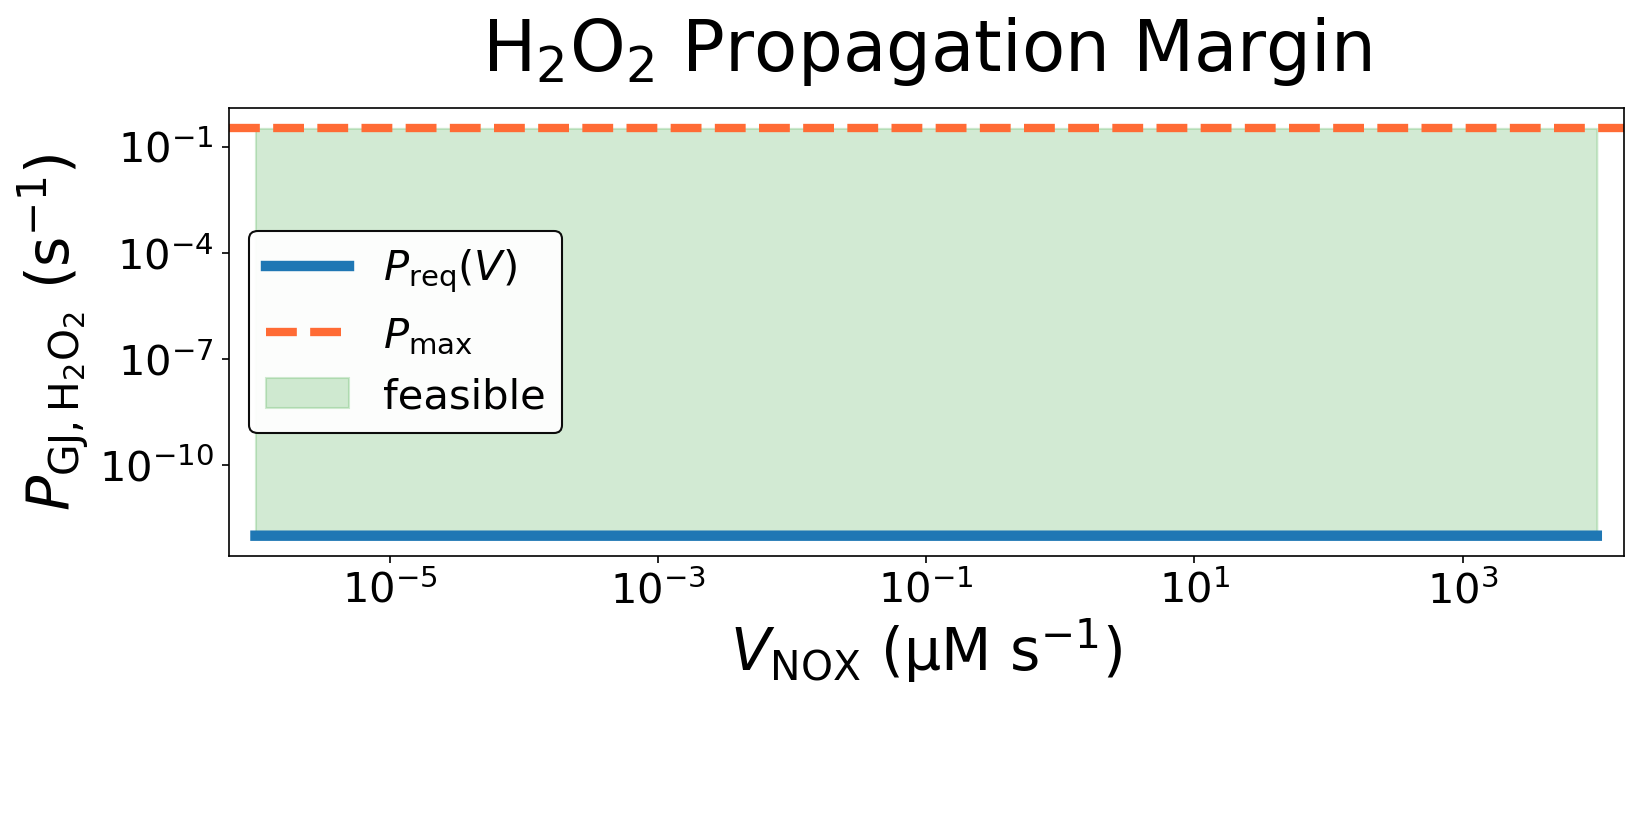

In [154]:
# === H2O2 propagation margin with multiple Vrefs + multi-V tornado ===
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter
import matplotlib.transforms as mtransforms

# ---------- Baseline numbers (edit if needed) ----------
kappa      = params_h["kappa_H"]  #3.47e-02      # s^-1  (effective H2O2 clearance)
dH_act_M   = params_h["dH_act"]  #9.90e-8     # M     (activation increment to reach NOX gate)
dH_nb_M    = params_h["dH_nb"]   #5.743e-12    # M     (neighbor H2O2 difference across GJ)
Pmax_const = params_h["Pmax_H"]    #3.319e-01    # s^-1  (your pore-physics ceiling)

# Try several NOX rates (µM s^-1) on the SAME plot:
Vrefs_uM_s = [1.0, 10.0, 100.0]          # add/remove values as you like
scale_low, scale_high = 0.1, 10.0        # tornado: down/up scaling factors

# ---------- Helpers ----------
def P_req(V_M_s, kappa, dH_act_M, dH_nb_M):
    """Required GJ coupling for propagation at drive V (M s^-1)."""
    return np.maximum((kappa * dH_act_M - V_M_s) / max(dH_nb_M, 1e-30), 1e-12)

def tex_sci(x, sig=3):
    if x == 0: return "0"
    e = int(np.floor(np.log10(abs(x))))
    m = x / 10**e
    return rf"{m:.{sig-1}f}\times 10^{{{e}}}"

def eng(x):
    """3-sig-fig engineering string."""
    if x == 0:
        return "0"
    exp = int(np.floor(np.log10(abs(x))))
    base = x / (10**exp)
    return f"{base:.3g}e{exp:+d}"

# Styling for poster
plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 34,
    "axes.labelsize": 28,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20
})

# ---------- Figure A: H2O2 propagation margin with 3-column footer (no overlap) ----------
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

V_M_s  = np.geomspace(1e-12, 1e-2, 1200)       # M s^-1
V_uM_s = V_M_s * 1e6
P_curve = P_req(V_M_s, kappa, dH_act_M, dH_nb_M)

V_star    = kappa * dH_act_M                   # M s^-1  (where P_req -> 0)
V_star_uM = V_star * 1e6
P0        = P_req(0.0, kappa, dH_act_M, dH_nb_M)

fig = plt.figure(figsize=(12, 6))

# outer grid: [main plot | spacer | footer]
outer = GridSpec(nrows=3, ncols=1, height_ratios=[8.0, 0.9, 2.7], hspace=0.10)

ax = fig.add_subplot(outer[0])        # main plot
sp = fig.add_subplot(outer[1])        # spacer row (empty)
sp.axis("off")

# footer split into three columns with generous spacing
footer = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[2], wspace=0.35)
ax_left   = fig.add_subplot(footer[0, 0]); ax_left.axis("off")
ax_center = fig.add_subplot(footer[0, 1]); ax_center.axis("off")
ax_right  = fig.add_subplot(footer[0, 2]); ax_right.axis("off")

# --- main plot content
line_req, = ax.loglog(V_uM_s, P_curve, lw=5, color="#1f77b4", label=r"$P_{\rm req}(V)$")
hline     = ax.axhline(Pmax_const, color="#FF6B35", lw=4, ls="--", label=r"$P_{\max}$")

# feasible region
feas = P_curve <= Pmax_const
feas_poly = ax.fill_between(V_uM_s, P_curve, Pmax_const, where=feas,
                            color="#4CAF50", alpha=0.25, interpolate=True, label="feasible")

# # Vref markers + collect lines for the right box
# colors = ["#640E23", "#6a3d9a", "#e31a1c", "#1b9e77", "#d95f02"]
# vref_lines = []
# for i, Vref_uM in enumerate(Vrefs_uM_s):
#     Vref_M = Vref_uM * 1e-6
#     Pref   = P_req(Vref_M, kappa, dH_act_M, dH_nb_M)
#     ax.axvline(Vref_uM, color=colors[i % len(colors)], ls=":", lw=5, alpha=0.85)
#     vref_lines.append(fr"$V={Vref_uM:g}\,\mu$M s$^{{-1}}$,  $P_{{\rm req}}={tex_sci(Pref)}$ s$^{{-1}}$")

# # V* marker
# ax.axvline(V_star_uM, color="k", lw=5, ls=":")
# vref_lines.append(rf"$V^{{\ast}}=\kappa\,\Delta H_{{\rm act}}={V_star_uM:.3g}\ \mu\mathrm{{M}}\ \mathrm{{s}}^{{-1}}$")

# titles/labels — pull xlabel UP so it never hits the footer
ax.set_title("H$_2$O$_2$ Propagation Margin", pad=18, zorder=10)
ax.set_xlabel(r"$V_{\rm NOX}$ (µM s$^{-1}$)", labelpad=2)  # smaller pad = higher label
ax.set_ylabel(r"$P_{\rm GJ,H_2O_2}$ (s$^{-1}$)")
ax.margins(x=0.02)

leg = ax.legend(loc="center left", frameon=True, fancybox=True, framealpha=0.95, edgecolor="black")
leg.get_frame().set_facecolor("white")

# log ticks (mathtext)
ax.set_xscale('log');  ax.set_yscale('log')
ax.xaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_major_formatter(LogFormatterMathtext())
ax.yaxis.set_major_formatter(LogFormatterMathtext())
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
ax.xaxis.set_minor_formatter(NullFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())

# # --- footer content
# # Left parameters box (anchor low in the footer)
# txt_left = (fr"$\kappa_{{\rm H2O2}}={tex_sci(kappa)}$ s$^{{-1}}$"+"\n"
#             fr"$\Delta H_{{\rm act}}={tex_sci(dH_act_M)}$ M"+"\n"
#             fr"$\Delta H_{{v+1}}={tex_sci(dH_nb_M)}$ M"+"\n"
#             fr"$P_{{\rm req}}(V=0)={tex_sci(P0)}$ s$^{{-1}}$")
# ax_left.text(0.00, 0.2, txt_left, ha="left", va="center",
#              bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black", lw=2, alpha=0.95))


# # Right Vref summary box
# ax_right.text(-1, -1, "\n".join(vref_lines), ha="left", va="center",
#               bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black", lw=2, alpha=0.95))

plt.show()


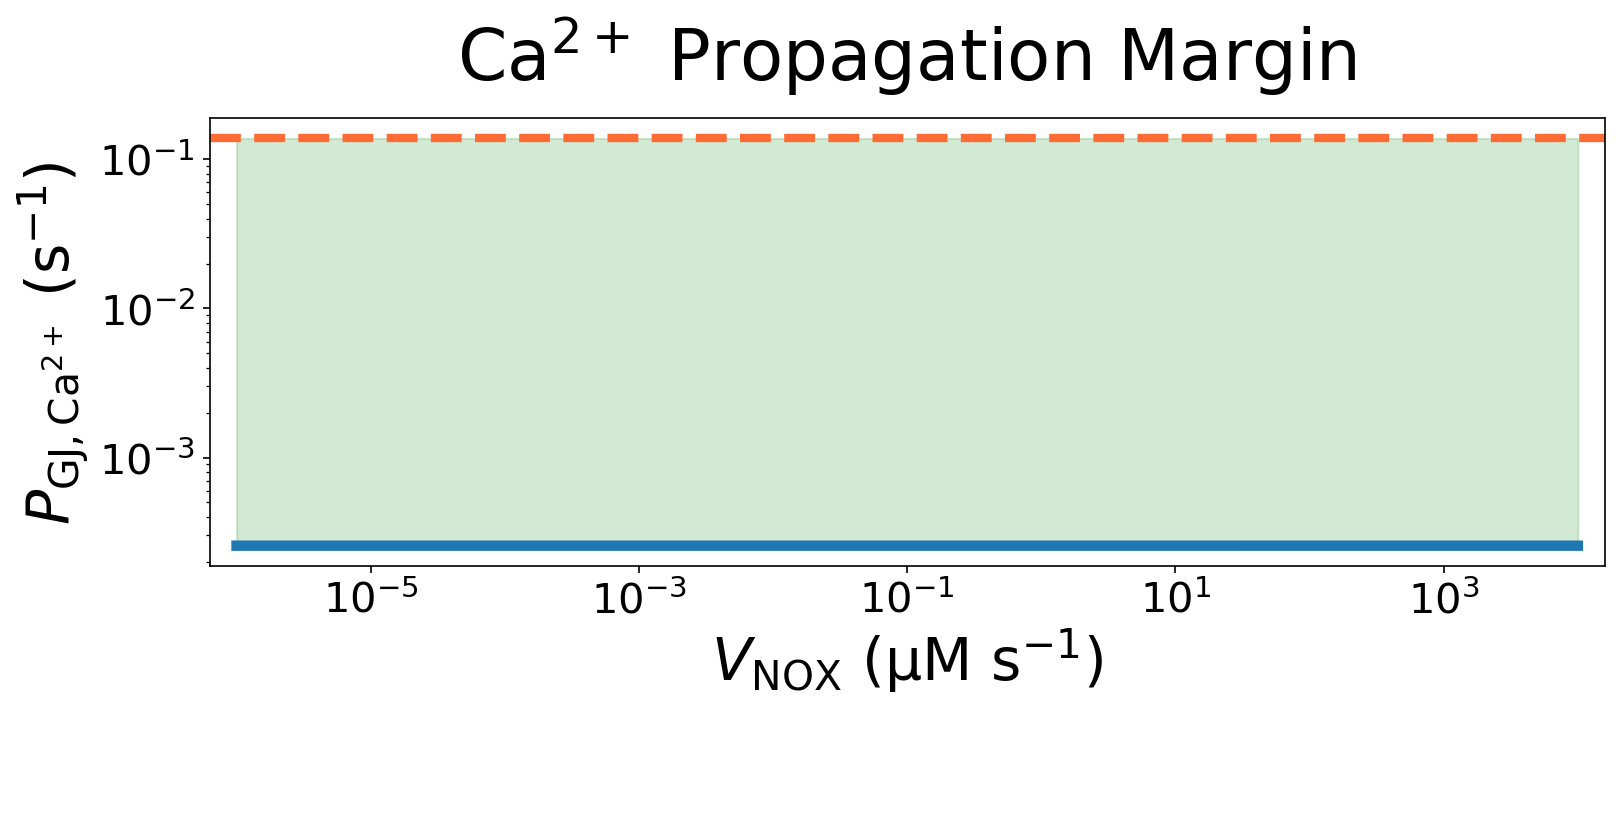

In [155]:
# === Ca2+ propagation margin with multiple Vrefs + multi-V tornado ===
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter, NullLocator

def kappa_from_baseline(k, x0, use_ss=False, T=300.0):
    """
    Estimate effective first-order H2O2 clearance rate κ (s^-1) at baseline.
    κ ≈ -∂(dH/dt)/∂H evaluated near baseline (or steady state if use_ss=True).
    """
    # Optionally relax to steady state first
    x_base = x0
    if use_ss:
        rhs = lambda t, y: model_noref(y, t, k, x0)
        sol = solve_ivp(rhs, (0.0, T), x0, t_eval=[T], method='Radau', atol=1e-9, rtol=1e-7)
        x_base = sol.y[:, -1]

    H0 = float(max(x_base[1], 1e-18))

    def fH(H):
        x = x_base.copy()
        x[1] = H
        return model_noref(x, 0.0, k, x_base)[1]

    dH = max(1e-3 * H0, 1e-12)
    slope = (fH(H0 + dH) - fH(H0 - dH)) / (2.0 * dH)
    kappa = max(-slope, 1e-12)  # ensure non-negative, avoid zero
    return kappa


def pmax_eff_curve_ca(k, x0, V_M_s, dC_act_M, alpha_gain, H_bolus=0.0, beta_gain_H=None):
    """
    Signal-dependent ceiling for Ca2+ GJ coupling:
      Pmax_eff(V) = k[71] * F_open(H*,C*) * G_close(C*)
    where C* = C0 + dC_act + α·V and H* = H0 + dH_act + β·V.
    beta_gain_H [M/(M s^-1)] defaults to 1/κ_H from the model.
    """
    H0, C0 = float(x0[1]), float(x0[29])

    # Map V -> ΔH via β ≈ 1/κ_H if not provided
    if beta_gain_H is None:
        kappa_H = kappa_from_baseline(k, x0)  # s^-1
        beta_gain_H = 1.0 / max(kappa_H, 1e-30)

    dH_act = max(float(k[33]) - H0, 0.0) + float(H_bolus)
    Hs = H0 + dH_act + beta_gain_H * V_M_s
    Cs = C0 + dC_act_M + alpha_gain * V_M_s

    fH = Hs / (k[74] + Hs)
    fC = Cs / (k[76] + Cs)
    F_open = 1.0 + (k[73]-1.0)*fH + (k[75]-1.0)*fC
    F_open = np.minimum(F_open, k[72])
    G_close = 1.0/(1.0 + (Cs/k[77])**k[78])

    return k[71] * F_open * G_close

# ---------- Baseline numbers (edit if needed) ----------
kappa_C     = params_ca["kappa_C"]    # s^-1   (effective Ca2+ clearance around baseline)
dC_act_M    = params_ca["dC_act"]    # M      (ΔC needed to hit NOX5 Ca half-activation)
dC_nb_M     = params_ca["dC_nb"]   # M      (neighbor CaΔ across GJ)
alpha_gain  = params_ca["alpha"]     # M / (M s^-1)  (H2O2/NOX drive -> Ca elevation gain)
Pmax_Ca    = params_ca["Pmax_Ca"]     # s^-1   (your pore-physics ceiling)
# Try several NOX rates (µM s^-1) on the SAME plot:
Vrefs_uM_s = [1.0, 10.0, 100.0]          # add/remove values as you like
scale_low, scale_high = 0.1, 10.0        # tornado: down/up scaling factors

# ---------- Helpers ----------
def P_req_Ca(V_M_s, kappa_C, dC_act_M, dC_nb_M, alpha_gain):
    """
    Required Ca2+ GJ coupling for propagation at drive V (M s^-1).
    """
    num = kappa_C * dC_act_M - alpha_gain * V_M_s
    return np.maximum(num / max(dC_nb_M, 1e-30), 1e-12)

def tex_sci(x, sig=3):
    if x == 0: return "0"
    e = int(np.floor(np.log10(abs(x))))
    m = x / 10**e
    return rf"{m:.{sig-1}f}\times 10^{{{e}}}"

# Poster styling (match your H2O2 cell)
plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 34,
    "axes.labelsize": 28,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20
})

# ---------- Ca2+ propagation margin with 3-column footer (no overlap) ----------
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

V_M_s  = np.geomspace(1e-12, 1e-2, 1200)   # M s^-1
V_uM_s = V_M_s * 1e6
P_curve = P_req_Ca(V_M_s, kappa_C, dC_act_M, dC_nb_M, alpha_gain)

V_star    = (kappa_C * dC_act_M) / max(alpha_gain, 1e-30)   # M/s
V_star_uM = V_star * 1e6
P0        = P_req_Ca(0.0, kappa_C, dC_act_M, dC_nb_M, alpha_gain)

fig = plt.figure(figsize=(12, 6))

# outer grid: [main plot | spacer | footer]
outer = GridSpec(nrows=3, ncols=1, height_ratios=[8.0, 0.9, 2.7], hspace=0.10)

ax = fig.add_subplot(outer[0])        # main plot
sp = fig.add_subplot(outer[1])        # spacer row
sp.axis("off")

# footer split into three columns with generous spacing
footer = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer[2], wspace=0.35)
ax_left   = fig.add_subplot(footer[0, 0]); ax_left.axis("off")
ax_center = fig.add_subplot(footer[0, 1]); ax_center.axis("off")
ax_right  = fig.add_subplot(footer[0, 2]); ax_right.axis("off")

# --- main plot
line_req, = ax.loglog(V_uM_s, P_curve, lw=5, color="#1f77b4", label=r"$P_{\rm req}(V)$")
hline     = ax.axhline(Pmax_Ca, color="#FF6B35", lw=4, ls="--", label=r"$P_{\max}$ by pore physics")

feas = P_curve <= Pmax_Ca
feas_poly = ax.fill_between(V_uM_s, P_curve, Pmax_Ca, where=feas,
                            color="#4CAF50", alpha=0.25, interpolate=True, label="feasible")

# colors = ["#640E23", "#6a3d9a", "#e31a1c", "#1b9e77", "#d95f02"]
# vref_lines = []
# for i, Vref_uM in enumerate(Vrefs_uM_s):
#     Vref_M = Vref_uM * 1e-6
#     Pref   = P_req_Ca(Vref_M, kappa_C, dC_act_M, dC_nb_M, alpha_gain)
#     ax.axvline(Vref_uM, color=colors[i % len(colors)], ls=":", lw=5, alpha=0.85)
#     vref_lines.append(fr"$V={Vref_uM:g}\,\mu$M s$^{{-1}}$,  $P_{{\rm req}}={tex_sci(Pref)}$ s$^{{-1}}$")

# ax.axvline(V_star_uM, color="k", lw=5, ls=":")
# vref_lines.append(rf"$V^{{\ast}}=\kappa_C\Delta C_{{\rm act}}/\alpha={tex_sci(V_star_uM)}\ \mu\mathrm{{M}}\ \mathrm{{s}}^{{-1}}$")

# titles/labels — bring xlabel UP (small/negative pad pulls it closer to the axis)
ax.set_title("Ca$^{2+}$ Propagation Margin", pad=18, zorder=10)
ax.set_xlabel(r"$V_{\rm NOX}$ (µM s$^{-1}$)", labelpad=2)  # <= smaller pad = higher label
ax.set_ylabel(r"$P_{\rm GJ,Ca^{2+}}$ (s$^{-1}$)")
ax.margins(x=0.02)

# leg = ax.legend(loc="center left", frameon=True, fancybox=True, framealpha=0.95, edgecolor="black")
# leg.get_frame().set_facecolor("white")
# log ticks
ax.set_xscale('log');  ax.set_yscale('log')
ax.xaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_major_formatter(LogFormatterMathtext())
ax.yaxis.set_major_formatter(LogFormatterMathtext())
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
ax.xaxis.set_minor_formatter(NullFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())

# # --- footer content (anchor lower to avoid touching xlabel)
# alpha_sec = alpha_gain
# txt_left = (fr"$\kappa_C={tex_sci(kappa_C)}$ s$^{-1}$"+"\n"
#             fr"$\Delta C_{{\rm act}}={tex_sci(dC_act_M)}$ M"+"\n"
#             fr"$\Delta C_{{\rm nb}}={tex_sci(dC_nb_M)}$ M"+"\n"
#             fr"$\alpha={tex_sci(alpha_sec)}$ s"+"\n"
#             fr"$P_{{\rm req}}(V=0)={tex_sci(P0)}$ s$^{-1}$")
# ax_left.text(0.00, .5, txt_left, ha="left", va="center",   # y=0.30 keeps it low in the footer
#              bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black", lw=2, alpha=0.95))

# ax_right.text(-0.5, 0.30, "\n".join(vref_lines), ha="left", va="center",
#               bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black", lw=2, alpha=0.95))


plt.show()

OP1:  H2O2 H=0, V*=0 µM/s   |   Ca H=0.00219, V*=7.77e+08 µM/s
OP2:  H2O2 H=0, V*=0 µM/s   |   Ca H=0.00365, V*=1.04e+09 µM/s
OP3:  H2O2 H=0, V*=0 µM/s   |   Ca H=0.00608, V*=1.29e+09 µM/s


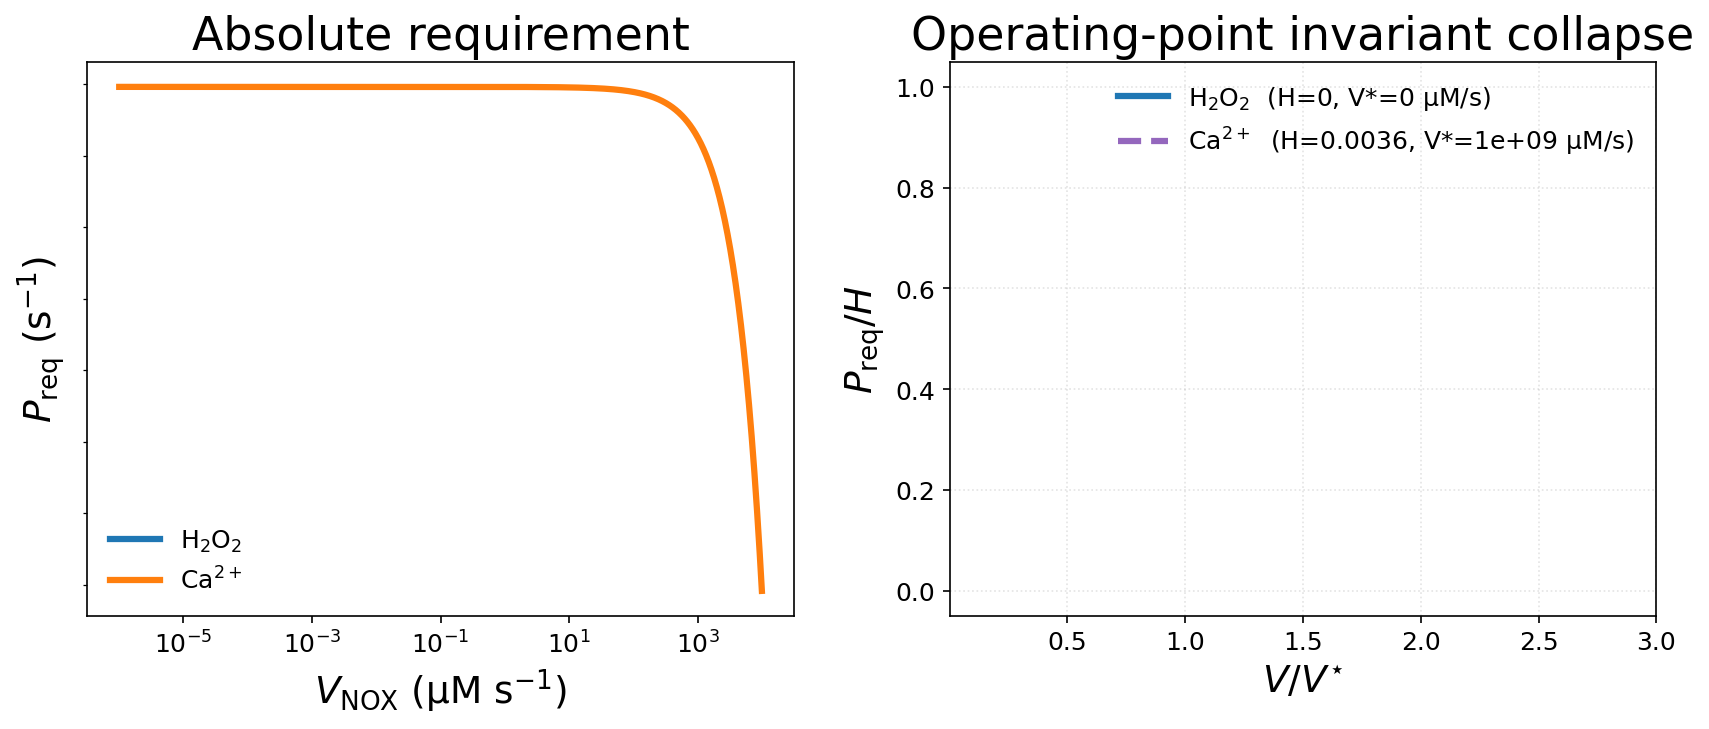

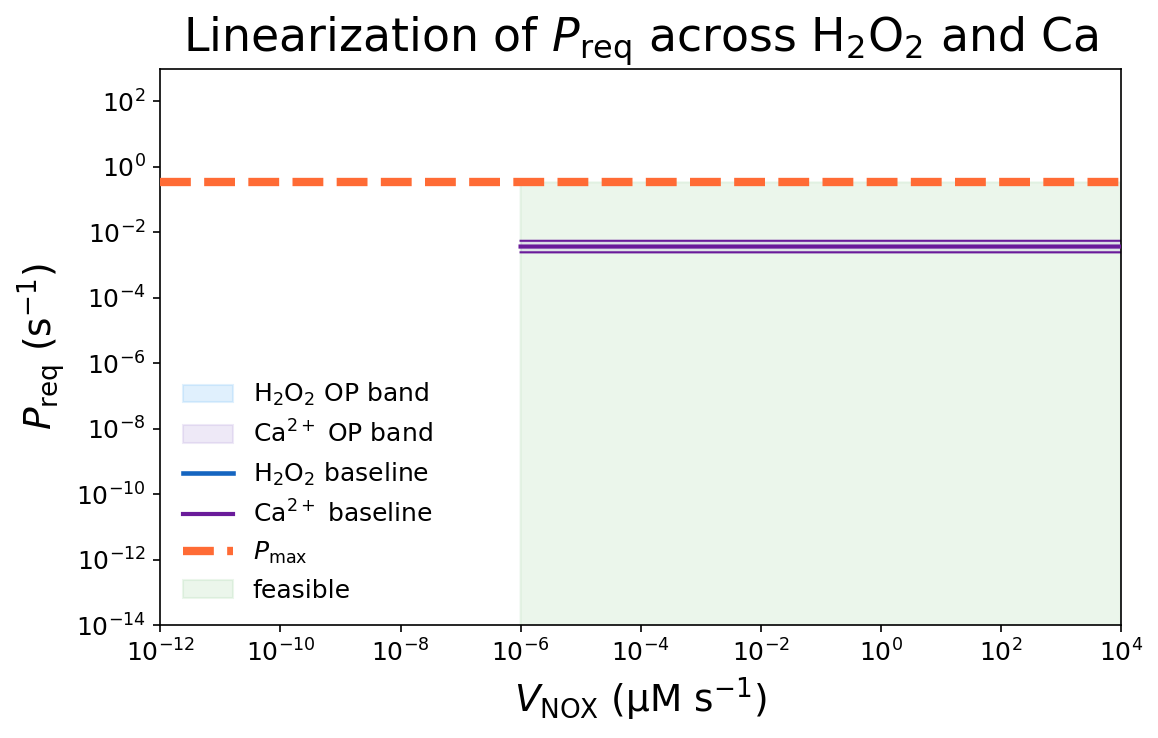

(<Figure size 1200x780 with 1 Axes>,
 <Axes: title={'center': 'Linearization of $P_{\\rm req}$ across H$_2$O$_2$ and Ca'}, xlabel='$V_{\\rm NOX}$ (µM s$^{-1}$)', ylabel='$P_{\\rm req}$ (s$^{-1}$)'>)

In [156]:
# ============================================================
# Linearized P_req utilities + OP listing + 3 plotting steps
# (self-contained, no heatmap; robust params; fixed feasible shading)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

# -----------------------------
# Helpers / parameter accessors
# -----------------------------
def _alias_param_dicts():
    """Make sure param_h/param_c exist, aliasing params_h/params_ca if needed."""
    g = globals()
    if "param_h" not in g and "params_h" in g:
        g["param_h"] = g["params_h"]
    if "param_c" not in g and "params_ca" in g:
        g["param_c"] = g["params_ca"]
    if "param_h" not in g: g["param_h"] = {}
    if "param_c" not in g: g["param_c"] = {}

def _get(d, *keys, default=None):
    """Fetch first present key from a dict as float; else default."""
    for k in keys:
        if k in d:
            return float(d[k])
    return default

def _get_params_dicts():
    """Return (param_h, param_c) from globals after aliasing."""
    _alias_param_dicts()
    ph = globals()["param_h"]; pc = globals()["param_c"]
    return ph, pc

# -----------------------------
# Optional: estimate from ODE to fill missing values
# -----------------------------
def _fit_kappa_H_from_tail(sol):
    t = np.asarray(sol.t, float)
    H = np.asarray(sol.y[1], float)
    if len(t) < 12: return None
    i0 = int(0.6*len(t))
    t_tail = t[i0:] - t[i0]
    Hinf = np.median(H[-max(5, len(H)//8):])
    Y = np.log(np.clip(np.abs(H[i0:] - Hinf), 1e-15, None))
    m, _ = np.polyfit(t_tail, Y, 1)
    return float(max(-m, 1e-12))

def _estimate_alpha_from_fd(k, x0, model, eps=0.05, T=300.0):
    """Rough α ≈ dC∞/dV via finite-difference on NOX5 Vmax as a proxy for V."""
    from scipy.integrate import solve_ivp
    def run(k_mod):
        def rhs(t,y): return model(y, t, k_mod, x0, H_nb=x0[1], Ca_nb=x0[29])
        sol = solve_ivp(rhs, (0,T), x0, t_eval=[T], method="Radau", atol=1e-9, rtol=1e-7)
        return float(sol.y[29,-1])
    V0 = float(k[48])
    C0 = run(k)
    k1 = k.copy(); k1[48] = V0*(1.0+eps)
    C1 = run(k1)
    dV = k1[48] - V0
    return max((C1 - C0)/dV, 1e-12)   # seconds

def calibrate_linearization_from_ode():
    """
    Fill missing/zero param_h/param_c entries from ODE or sensible defaults:
      param_h: kappa_H, dH_act (K_act - H_rest), dH_nb
      param_c: alpha, dC_nb
    """
    _alias_param_dicts()
    ph, pc = params_h, params_ca
    g = globals()

    # H2O2
    if "kappa_H" not in ph or ph["kappa_H"] <= 0:
        if "sol" in g:
            kH = _fit_kappa_H_from_tail(g["sol"])
            if kH: ph["kappa_H"] = kH
    if ("dH_act" not in ph) and ("dH_act_M" not in ph):
        H_rest = float(g["sol"].y[1,-1]) if "sol" in g else 1e-9
        Kact   = float(g.get("k", np.zeros(100))[33]) if "k" in g else 1e-7
        ph["dH_act"] = max(Kact - H_rest, 1e-12)
    if ("dH_nb" not in ph) and ("dH_nb_M" not in ph):
        ph["dH_nb"] = 5.7e-10  # tune to geometry

    # Ca
    if ("alpha" not in pc) and ("alpha_gain" not in pc):
        if all(name in g for name in ("k","x0","model_noref")):
            a = _estimate_alpha_from_fd(g["k"], g["x0"], g["model_noref"])
            if a: pc["alpha"] = a
    if float(pc.get("alpha", pc.get("alpha_gain", 0.0))) <= 0:
        pc["alpha"] = 5.36e-9   # seconds (baseline)
    if ("dC_nb" not in pc) and ("dC_nb_M" not in pc):
        pc["dC_nb"] = 1.7e-6

# -----------------------------
# Build linearized A,B,D objects (not-aware)
# -----------------------------
def build_abd_from_params(N_eff=1.0, Vloc_Ca_Ms=0.0):
    """
    Return dicts H2O2 and Ca with A,B,D,H,Vstar and callable P_req(V).
    Not-aware linearization:
      H2O2:  P_req = (kappa_H*ΔH_act - V) / (N_eff*ΔH_nb)
      Ca   : P_req = (kappa_C*ΔC_act - Vloc - α*V) / (N_eff*ΔC_nb)
    """
    ph, pc = _get_params_dicts()

    # H2O2
    kappa_H = _get(ph, "kappa_H")
    dH_act  = _get(ph, "dH_act", "dH_act_M")
    dH_nb   = _get(ph, "dH_nb",  "dH_nb_M")
    if None in (kappa_H, dH_act, dH_nb) or kappa_H <= 0:
        calibrate_linearization_from_ode()
        ph, pc = _get_params_dicts()
        kappa_H = _get(ph, "kappa_H", default=1e-2)
        dH_act  = _get(ph, "dH_act","dH_act_M", default=1e-7)
        dH_nb   = _get(ph, "dH_nb", "dH_nb_M", default=5.7e-10)
    A_H = kappa_H * dH_act
    B_H = 1.0
    D_H = N_eff * dH_nb
    H2O2 = dict(A=A_H, B=B_H, D=D_H)
    H2O2["H"]     = A_H / max(D_H, 1e-30)
    H2O2["Vstar"] = A_H / max(B_H, 1e-30)
    H2O2["P_req"] = lambda V: np.maximum((A_H - B_H*np.asarray(V))/max(D_H,1e-30), 0.0)

    # Ca
    kappa_C = _get(pc, "kappa_C", default=1e-4)
    dC_act  = _get(pc, "dC_act", "dC_act_M", default=6e-7)
    dC_nb   = _get(pc, "dC_nb",  "dC_nb_M",  default=1.7e-6)
    alpha   = _get(pc, "alpha",  "alpha_gain", default=5.36e-9)
    A_C = kappa_C * dC_act - float(Vloc_Ca_Ms)
    B_C = alpha
    D_C = N_eff * dC_nb
    Ca = dict(A=A_C, B=B_C, D=D_C, Vloc=Vloc_Ca_Ms)
    Ca["H"]     = A_C / max(D_C, 1e-30)
    Ca["Vstar"] = A_C / max(B_C, 1e-30)
    Ca["P_req"] = lambda V: np.maximum((A_C - B_C*np.asarray(V))/max(D_C,1e-30), 0.0)

    return H2O2, Ca

def collapse_curve(V, A, B, D):
    """Normalized axes: V~ = V/V*,  P~ = P_req/H (H = A/D, V* = A/B)."""
    V = np.asarray(V, float)
    H = A / max(D, 1e-30)
    Vstar = A / max(B, 1e-30)
    P_req = np.maximum((A - B*V)/max(D,1e-30), 0.0)
    return V / max(Vstar,1e-30), P_req / max(H,1e-30), H, Vstar

# -----------------------------
# OP listing utility
# -----------------------------
def list_operating_points(ops_h=None, ops_c=None, N_eff=1.0, Vloc_Ca_Ms=0.0):
    """Build OPs and report H (=A/D) and V* (=A/B)."""
    _alias_param_dicts()
    ph0 = globals()["param_h"]; pc0 = globals()["param_c"]

    if ops_h is None or ops_c is None:
        scales = [0.75, 1.0, 1.25]
        ops_h, ops_c = [], []
        for s in scales:
            ph = dict(ph0); pc = dict(pc0)
            if "kappa_H" in ph: ph["kappa_H"] *= s
            if "kappa_C" in pc: pc["kappa_C"] *= s
            for key in ("dH_nb","dH_nb_M"):
                if key in ph: ph[key] *= (2 - s)
            for key in ("dC_nb","dC_nb_M"):
                if key in pc: pc[key] *= (2 - s)
            ops_h.append(ph); ops_c.append(pc)

    rows = []
    for i,(ph,pc) in enumerate(zip(ops_h, ops_c), start=1):
        bak_h, bak_c = globals().get("param_h"), globals().get("param_c")
        globals()["param_h"], globals()["param_c"] = ph, pc
        try:
            H2O2, Ca = build_abd_from_params(N_eff=N_eff, Vloc_Ca_Ms=Vloc_Ca_Ms)
        finally:
            if bak_h is None: del globals()["param_h"]
            else: globals()["param_h"] = bak_h
            if bak_c is None: del globals()["param_c"]
            else: globals()["param_c"] = bak_c

        rows.append({
            "OP": i,
            "H2O2_H (s^-1)": H2O2["H"],
            "H2O2_V* (µM/s)": H2O2["Vstar"]*1e6,
            "Ca_H (s^-1)":    Ca["H"],
            "Ca_V* (µM/s)":   Ca["Vstar"]*1e6,
        })
    return rows

# -----------------------------
# STEP 1 — Absolute + normalized collapse
# -----------------------------
def step1_abs_and_collapse(V_M_s=None, N_eff=1.0, Vloc_Ca_Ms=0.0, title_suffix=""):
    if V_M_s is None: V_M_s = np.geomspace(1e-12, 1e-2, 1200)
    V_uM_s = V_M_s*1e6
    H2O2, Ca = build_abd_from_params(N_eff=N_eff, Vloc_Ca_Ms=Vloc_Ca_Ms)

    plt.rcParams.update({"font.size": 16, "axes.titlesize": 22, "axes.labelsize": 18,
                         "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12})
    fig, (ax_abs, ax_norm) = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"wspace":0.22})

    ax_abs.loglog(V_uM_s, H2O2["P_req"](V_M_s), lw=3, label="H$_2$O$_2$")
    ax_abs.loglog(V_uM_s, Ca["P_req"](V_M_s),   lw=3, label="Ca$^{2+}$")
    ax_abs.set_xlabel(r"$V_{\rm NOX}$ (µM s$^{-1}$)"); ax_abs.set_ylabel(r"$P_{\rm req}$ (s$^{-1}$)")
    ax_abs.xaxis.set_major_locator(LogLocator(base=10)); ax_abs.yaxis.set_major_locator(LogLocator(base=10))
    ax_abs.xaxis.set_major_formatter(LogFormatterMathtext()); ax_abs.yaxis.set_major_formatter(LogFormatterMathtext())
    ax_abs.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
    ax_abs.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
    ax_abs.xaxis.set_minor_formatter(NullFormatter()); ax_abs.yaxis.set_minor_formatter(NullFormatter())
    ax_abs.legend(frameon=False); ax_abs.set_title("Absolute requirement"+(" — "+title_suffix if title_suffix else ""))

    for (lbl, dct, col, style) in [("H$_2$O$_2$", H2O2, "#1f77b4", "-"), ("Ca$^{2+}$", Ca, "#9467bd", "--")]:
        Vt, Pt, H, Vstar = collapse_curve(V_M_s, dct["A"], dct["B"], dct["D"])
        ax_norm.plot(Vt, Pt, lw=3, ls=style, color=col, label=f"{lbl}  (H={H:.2g}, V*={Vstar*1e6:.2g} µM/s)")
    ax_norm.set_xlabel(r"$V/V^{\star}$"); ax_norm.set_ylabel(r"$P_{\rm req}/H$")
    ax_norm.set_xlim(1e-3, 3); ax_norm.set_ylim(-0.05, 1.05)
    ax_norm.grid(True, ls=":", alpha=0.35); ax_norm.legend(frameon=False)
    ax_norm.set_title("Operating-point invariant collapse")

    plt.show()
    return fig, (ax_abs, ax_norm)

# -----------------------------
# STEP 2 — State ribbons (OP bands)
# -----------------------------
def step2_state_ribbon(ops_h=None, ops_c=None, V_M_s=None, N_eff=1.0, Vloc_Ca_Ms=0.0,
                       Pmax_const=None, both_must_hold=False, xlim=(1e-12,1e4)):
    """
    Plot OP ribbons (min–max across OPs) and baseline curves; shade feasibility vs Pmax.
    both_must_hold=False -> feasible if EITHER path can propagate (min of the two).
    both_must_hold=True  -> feasible only if BOTH can (max of the two).
    """
    if V_M_s is None: V_M_s = np.geomspace(1e-12, 1e-2, 1200)
    V_uM_s = V_M_s*1e6
    if Pmax_const is None: Pmax_const = float(globals().get("Pmax_const", 0.214))

    ph0, pc0 = _get_params_dicts()

    def _ABD_from(ph, pc):
        bak_h, bak_c = globals().get("param_h"), globals().get("param_c")
        globals()["param_h"], globals()["param_c"] = ph, pc
        try:    return build_abd_from_params(N_eff=N_eff, Vloc_Ca_Ms=Vloc_Ca_Ms)
        finally:
            if bak_h is None: del globals()["param_h"]
            else: globals()["param_h"] = bak_h
            if bak_c is None: del globals()["param_c"]
            else: globals()["param_c"] = bak_c

    # OP lists
    if ops_h is None or ops_c is None:
        scales = [0.8, 1.0, 1.2]
        ops_h, ops_c = [], []
        for s in scales:
            ph = dict(ph0); pc = dict(pc0)
            if "kappa_H" in ph: ph["kappa_H"] *= s
            if "kappa_C" in pc: pc["kappa_C"] *= s
            for key in ("dH_nb","dH_nb_M"):
                if key in ph: ph[key] *= (2 - s)
            for key in ("dC_nb","dC_nb_M"):
                if key in pc: pc[key] *= (2 - s)
            ops_h.append(ph); ops_c.append(pc)

    # Stack ribbons
    Ph_list, Pc_list = [], []
    for ph, pc in zip(ops_h, ops_c):
        H2O2_i, Ca_i = _ABD_from(ph, pc)
        Ph_list.append(H2O2_i["P_req"](V_M_s))
        Pc_list.append(Ca_i  ["P_req"](V_M_s))
    Ph = np.vstack(Ph_list); Pc = np.vstack(Pc_list)

    # Baseline
    H2O2, Ca = build_abd_from_params(N_eff=N_eff, Vloc_Ca_Ms=Vloc_Ca_Ms)
    P_h_base = H2O2["P_req"](V_M_s);  P_c_base = Ca["P_req"](V_M_s)

    # Which constraint sets feasibility?
    P_ref = np.maximum(P_h_base, P_c_base) if both_must_hold else np.minimum(P_h_base, P_c_base)

    # Plot
    fig, ax = plt.subplots(figsize=(8,5.2))
    ax.fill_between(V_uM_s, Ph.min(0), Ph.max(0), color="#90caf9", alpha=0.28, label="H$_2$O$_2$ OP band", zorder=1)
    ax.plot(V_uM_s, Ph.min(0), color="#1e88e5", lw=1.2, zorder=2)
    ax.plot(V_uM_s, Ph.max(0), color="#1e88e5", lw=1.2, zorder=2)

    ax.fill_between(V_uM_s, Pc.min(0), Pc.max(0), color="#b39ddb", alpha=0.22, label="Ca$^{2+}$ OP band", zorder=1)
    ax.plot(V_uM_s, Pc.min(0), color="#6a1b9a", lw=1.0, zorder=2)
    ax.plot(V_uM_s, Pc.max(0), color="#6a1b9a", lw=1.0, zorder=2)

    ax.loglog(V_uM_s, P_h_base, color="#1565c0", lw=2.2, label="H$_2$O$_2$ baseline", zorder=3)
    ax.loglog(V_uM_s, P_c_base, color="#6a1b9a", lw=2.0, label="Ca$^{2+}$ baseline", zorder=3)

    ax.axhline(Pmax_const, color="#FF6B35", lw=4, ls="--", label=r"$P_{\max}$", zorder=4)

    feas = P_ref <= Pmax_const
    ax.fill_between(V_uM_s, P_ref, Pmax_const, where=feas, color="#a5d6a7", alpha=0.22,
                    interpolate=True, label="feasible", zorder=0)

    # Cosmetics
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$V_{\rm NOX}$ (µM s$^{-1}$)")
    ax.set_ylabel(r"$P_{\rm req}$ (s$^{-1}$)")
    ax.xaxis.set_major_locator(LogLocator(base=10)); ax.yaxis.set_major_locator(LogLocator(base=10))
    ax.xaxis.set_major_formatter(LogFormatterMathtext()); ax.yaxis.set_major_formatter(LogFormatterMathtext())
    ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
    ax.xaxis.set_minor_formatter(NullFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(*xlim)
    ax.set_ylim(1e-14, 1e3)
    ax.legend(frameon=False, loc="lower left")
    ax.set_title(r"Linearization of $P_{\rm req}$ across H$_2$O$_2$ and Ca")
    plt.tight_layout(); plt.show()
    return fig, ax

# -----------------------------
# STEP 3 — Knee V*(t) from ODE snapshots
# -----------------------------
def step3_knee_vs_time(times=None, N_eff=1.0, Vloc_Ca_Ms=0.0):
    """Plot V*(t) from ODE snapshots; fallback to constants if sol/k/model_noref absent."""
    # ensure param dicts exist; build baseline ABD
    ph, pc = _get_params_dicts()
    H2O2, Ca = build_abd_from_params(N_eff=N_eff, Vloc_Ca_Ms=Vloc_Ca_Ms)
    VstarH_const, VstarC_const = H2O2["Vstar"], Ca["Vstar"]

    sol = globals().get("sol"); k = globals().get("k"); model = globals().get("model_noref")
    have_ode = (sol is not None) and (k is not None) and callable(model)

    if not have_ode:
        t = np.linspace(0, 300, 200)
        plt.figure(figsize=(7.2,3.8))
        plt.plot(t, np.full_like(t, VstarH_const*1e6), label=r"$V_H^{\star}$ (µM/s)")
        plt.plot(t, np.full_like(t, VstarC_const*1e6), label=r"$V_C^{\star}$ (µM/s)")
        plt.ylabel(r"$V^{\star}(t)$ (µM s$^{-1}$)"); plt.xlabel("time (s)")
        plt.title("Knee vs time (fallback: current params)")
        plt.legend(frameon=False); plt.tight_layout(); plt.show()
        return

    # local slope helpers
    def kappa_H_from_state(x_state):
        x0 = x_state.copy(); H0 = max(float(x0[1]), 1e-18)
        def fH(H): xx = x0.copy(); xx[1]=H; return float(model(xx, 0.0, k, x0)[1])
        dH = max(1e-3*H0, 1e-12); m = (fH(H0+dH)-fH(H0-dH))/(2*dH)
        return max(-m, 1e-12)

    def kappa_C_from_state(x_state):
        C, Cer = max(float(x_state[29]), 1e-18), max(float(x_state[31]), 0.0)
        Vser,Kser,n = k[38],k[39],k[47]; cap = max(0.0, 1.0 - Cer/k[55])
        Cn,Kn = C**n, Kser**n; den = Kn+Cn
        dHill = 0.0 if C<=0 else n*Kn*(C**(n-1))/den**2
        dJser = Vser*dHill*cap; kout, Km = k[58], 5e-6
        dJout = kout*Km/(Km+C)**2
        return max(dJser + dJout, 1e-12)

    def deltas_from_state(x_state):
        H_rest = float(x_state[1]); C_rest = float(x_state[29])
        dH = max(_get(ph,"dH_act","dH_act_M", default=k[33]) - H_rest, 0.0)
        Kc, m = k[49], k[50]; f = 0.10
        C_act = Kc * (f/(1-f))**(1.0/m)
        dC = max(C_act - C_rest, 0.0)
        return dH, dC

    t_all = np.asarray(sol.t)
    if times is None:
        idx = np.linspace(0, len(t_all)-1, 40).astype(int)
    else:
        idx = np.array([int(np.argmin(np.abs(t_all - tt))) for tt in np.asarray(times)])
    Vstar_H, Vstar_C = [], []
    for i in idx:
        x = sol.y[:, i]
        A_H = kappa_H_from_state(x) * deltas_from_state(x)[0]            # B_H = 1
        A_C = kappa_C_from_state(x) * deltas_from_state(x)[1] / Ca["B"]  # divide by alpha for V*
        Vstar_H.append(A_H); Vstar_C.append(A_C)

    plt.figure(figsize=(7.2,3.8))
    plt.plot(t_all[idx], np.array(Vstar_H)*1e6, label=r"$V_H^{\star}(t)$")
    plt.plot(t_all[idx], np.array(Vstar_C)*1e6, label=r"$V_C^{\star}(t)$")
    plt.axhline(VstarH_const*1e6, color="#1f77b4", ls="--", lw=1, alpha=0.6)
    plt.axhline(VstarC_const*1e6, color="#6a3d9a", ls="--", lw=1, alpha=0.6)
    plt.ylabel(r"$V^{\star}(t)$ (µM s$^{-1}$)"); plt.xlabel("time (s)")
    plt.title("Knee vs time (quasi-steady from ODE snapshots)")
    plt.legend(frameon=False); plt.tight_layout(); plt.show()

# -----------------------------
# Example driver
# -----------------------------
# Effective neighbors / local Ca source
N_eff_used   = 4.0
Vloc_Ca_used = 0.0

# Calibrate missing params once (uses ODE if available)
calibrate_linearization_from_ode()

# Print OP summary
ops = list_operating_points(N_eff=N_eff_used, Vloc_Ca_Ms=Vloc_Ca_used)
for r in ops:
    print(f"OP{r['OP']}:  H2O2 H={r['H2O2_H (s^-1)']:.3g}, V*={r['H2O2_V* (µM/s)']:.3g} µM/s   |   "
          f"Ca H={r['Ca_H (s^-1)']:.3g}, V*={r['Ca_V* (µM/s)']:.3g} µM/s")

# Run plots
V_grid = np.geomspace(1e-12, 1e-2, 1200)
step1_abs_and_collapse(V_M_s=V_grid, N_eff=N_eff_used, Vloc_Ca_Ms=Vloc_Ca_used)
step2_state_ribbon(V_M_s=V_grid, N_eff=N_eff_used, Vloc_Ca_Ms=Vloc_Ca_used,
                   Pmax_const=float(globals().get("Pmax_const", 0.214)),
                   both_must_hold=False, xlim=(1e-12, 1e4))
# step3_knee_vs_time(N_eff=N_eff_used, Vloc_Ca_Ms=Vloc_Ca_used)  # enable if sol/k/model_noref exist


OP1:  H2O2 H=0, V*=0 µM/s   |   Ca H=0.00219, V*=7.77e+08 µM/s
OP2:  H2O2 H=0, V*=0 µM/s   |   Ca H=0.00365, V*=1.04e+09 µM/s
OP3:  H2O2 H=0, V*=0 µM/s   |   Ca H=0.00608, V*=1.29e+09 µM/s


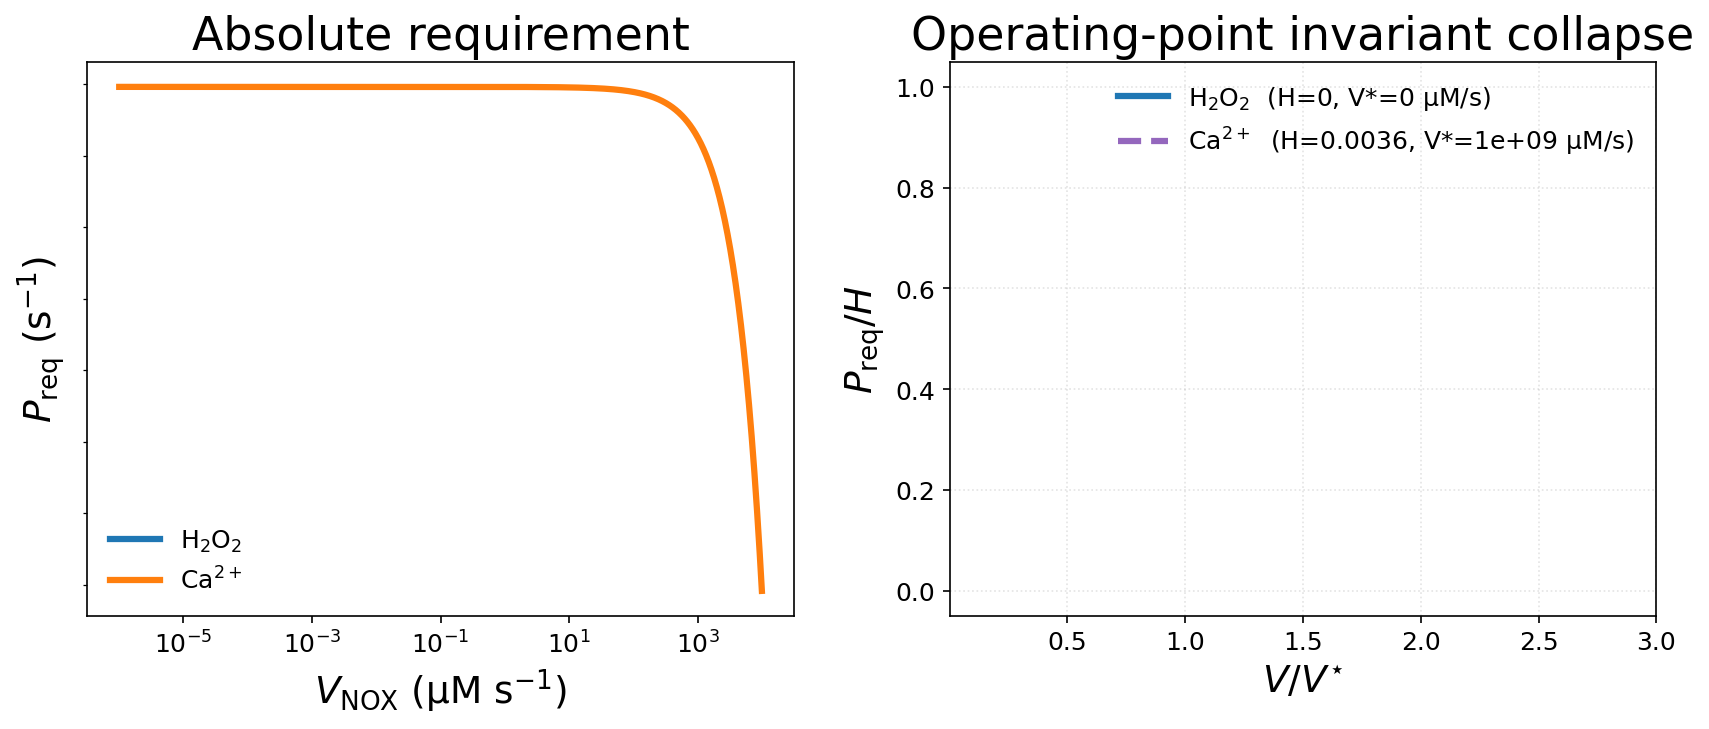

H2O2: H=0 s^-1,  V*=0 µM/s
Ca  : H=0.00365 s^-1,  V*=1.04e+09 µM/s
Pmax = 0.3319160934010085  s^-1


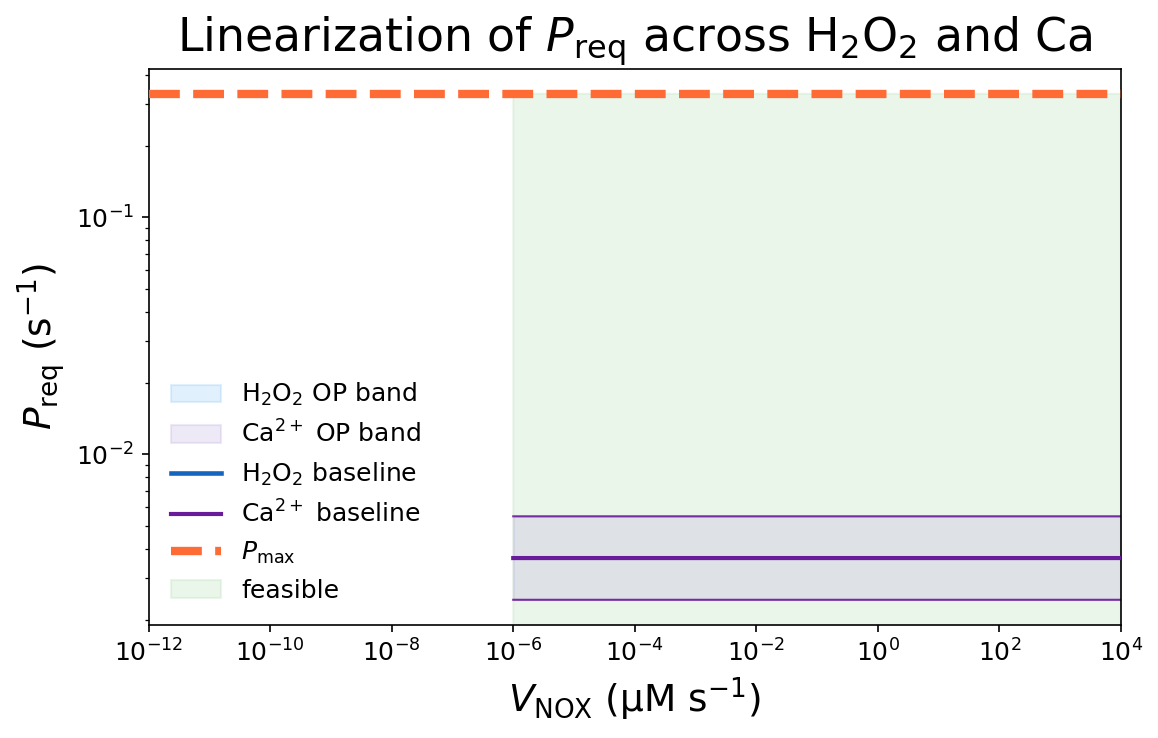

(<Figure size 1200x780 with 1 Axes>,
 <Axes: title={'center': 'Linearization of $P_{\\rm req}$ across H$_2$O$_2$ and Ca'}, xlabel='$V_{\\rm NOX}$ (µM s$^{-1}$)', ylabel='$P_{\\rm req}$ (s$^{-1}$)'>)

In [157]:
# ============================================================
# Linearized P_req utilities + OP listing + 3 plotting steps
# (cleaned, self-contained, no heatmap; fixed feasible shading)
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

# -----------------------------
# Helpers / parameter accessors
# -----------------------------
def _get(d, *keys, default=None):
    """Fetch first present key from a dict as float; else default."""
    for k in keys:
        if k in d: 
            return float(d[k])
    return default

def _get_params_dicts():
    """Return (param_h, param_c) from globals (or their params_* aliases)."""
    ph = globals().get("param_h") or globals().get("params_h")
    pc = globals().get("param_c") or globals().get("params_ca")
    if ph is None or pc is None:
        raise RuntimeError("Need param_h/param_c (or params_h/params_ca) in scope.")
    return ph, pc

# -----------------------------
# Build linearized A,B,D objects
# -----------------------------
def build_abd_from_params(N_eff=1.0, Vloc_Ca_Ms=0.0):
    """
    Return dicts H2O2 and Ca with A,B,D,H,Vstar and callable P_req(V).
    Not-aware linearization:
      H2O2:  P_req = (kappa_H*ΔH_act - V) / (N_eff*ΔH_nb)
      Ca   : P_req = (kappa_C*ΔC_act - Vloc - α*V) / (N_eff*ΔC_nb)
    """
    ph, pc = _get_params_dicts()

    # H2O2
    kappa_H = _get(ph, "kappa_H")
    dH_act  = _get(ph, "dH_act", "dH_act_M")
    dH_nb   = _get(ph, "dH_nb",  "dH_nb_M")
    if None in (kappa_H, dH_act, dH_nb):
        raise RuntimeError("param_h must contain kappa_H, dH_act, dH_nb.")
    A_H = kappa_H * dH_act
    B_H = 1.0
    D_H = N_eff   * dH_nb
    H2O2 = dict(A=A_H, B=B_H, D=D_H)
    H2O2["H"]     = A_H / max(D_H, 1e-30)
    H2O2["Vstar"] = A_H / max(B_H, 1e-30)
    H2O2["P_req"] = lambda V: np.maximum((A_H - B_H*np.asarray(V))/max(D_H,1e-30), 0.0)

    # Ca
    kappa_C = _get(pc, "kappa_C")
    dC_act  = _get(pc, "dC_act", "dC_act_M")
    dC_nb   = _get(pc, "dC_nb",  "dC_nb_M")
    alpha   = _get(pc, "alpha",  "alpha_gain")
    if None in (kappa_C, dC_act, dC_nb, alpha):
        raise RuntimeError("param_c must contain kappa_C, dC_act, dC_nb, alpha.")
    A_C = kappa_C * dC_act - float(Vloc_Ca_Ms)
    B_C = alpha
    D_C = N_eff   * dC_nb
    Ca = dict(A=A_C, B=B_C, D=D_C, Vloc=Vloc_Ca_Ms)
    Ca["H"]     = A_C / max(D_C, 1e-30)
    Ca["Vstar"] = A_C / max(B_C, 1e-30)
    Ca["P_req"] = lambda V: np.maximum((A_C - B_C*np.asarray(V))/max(D_C,1e-30), 0.0)

    return H2O2, Ca

def collapse_curve(V, A, B, D):
    """
    Normalized axes for OP-invariant overlay:
        V~ = V / V*,  P~ = P_req / H,  with H=A/D, V*=A/B.
    """
    V = np.asarray(V, float)
    H = A / max(D, 1e-30)
    Vstar = A / max(B, 1e-30)
    P_req = np.maximum((A - B*V)/max(D,1e-30), 0.0)
    return V / max(Vstar,1e-30), P_req / max(H,1e-30), H, Vstar

# -----------------------------
# OP listing utility
# -----------------------------
def list_operating_points(ops_h=None, ops_c=None, N_eff=1.0, Vloc_Ca_Ms=0.0):
    """
    Build a small set of operating points (param dicts) and report H (=A/D) and V* (=A/B).
    If ops_h/ops_c not given, synthesize 3 OPs by scaling kappa and counter-scaling Δ(nb).
    """
    ph0 = globals().get("param_h") or globals().get("params_h")
    pc0 = globals().get("param_c") or globals().get("params_ca")
    if ph0 is None or pc0 is None:
        raise RuntimeError("Need param_h/param_c (or params_h/params_ca) in scope.")

    # Synthesize a few OPs around baseline if not provided
    if ops_h is None or ops_c is None:
        scales = [0.75, 1.0, 1.25]
        ops_h, ops_c = [], []
        for s in scales:
            ph = dict(ph0); pc = dict(pc0)
            if "kappa_H" in ph: ph["kappa_H"] *= s
            if "kappa_C" in pc: pc["kappa_C"] *= s
            for key in ("dH_nb","dH_nb_M"):
                if key in ph: ph[key] *= (2 - s)  # counter-variation
            for key in ("dC_nb","dC_nb_M"):
                if key in pc: pc[key] *= (2 - s)
            ops_h.append(ph); ops_c.append(pc)

    rows = []
    for i,(ph,pc) in enumerate(zip(ops_h, ops_c), start=1):
        # temporarily swap to reuse builder
        _bak_h, _bak_c = globals().get("param_h"), globals().get("param_c")
        globals()["param_h"], globals()["param_c"] = ph, pc
        try:
            H2O2, Ca = build_abd_from_params(N_eff=N_eff, Vloc_Ca_Ms=Vloc_Ca_Ms)
        finally:
            if _bak_h is None: del globals()["param_h"]
            else: globals()["param_h"] = _bak_h
            if _bak_c is None: del globals()["param_c"]
            else: globals()["param_c"] = _bak_c

        rows.append({
            "OP": i,
            "H2O2_H (s^-1)": H2O2["H"],
            "H2O2_V* (µM/s)": H2O2["Vstar"]*1e6,
            "Ca_H (s^-1)":    Ca["H"],
            "Ca_V* (µM/s)":   Ca["Vstar"]*1e6,
        })
    return rows

# -----------------------------
# STEP 1 — Absolute + normalized collapse
# -----------------------------
def step1_abs_and_collapse(V_M_s=None, N_eff=1.0, Vloc_Ca_Ms=0.0, title_suffix=""):
    if V_M_s is None:
        V_M_s = np.geomspace(1e-12, 1e-2, 1200)
    V_uM_s = V_M_s*1e6

    H2O2, Ca = build_abd_from_params(N_eff=N_eff, Vloc_Ca_Ms=Vloc_Ca_Ms)

    plt.rcParams.update({
        "font.size": 16, "axes.titlesize": 22, "axes.labelsize": 18,
        "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12
    })
    fig, (ax_abs, ax_norm) = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw={"wspace":0.22})

    # Absolute curves
    ax_abs.loglog(V_uM_s, H2O2["P_req"](V_M_s), lw=3, label="H$_2$O$_2$")
    ax_abs.loglog(V_uM_s, Ca["P_req"](V_M_s),   lw=3, label="Ca$^{2+}$")
    ax_abs.set_xlabel(r"$V_{\rm NOX}$ (µM s$^{-1}$)")
    ax_abs.set_ylabel(r"$P_{\rm req}$ (s$^{-1}$)")
    ax_abs.xaxis.set_major_locator(LogLocator(base=10))
    ax_abs.yaxis.set_major_locator(LogLocator(base=10))
    ax_abs.xaxis.set_major_formatter(LogFormatterMathtext())
    ax_abs.yaxis.set_major_formatter(LogFormatterMathtext())
    ax_abs.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
    ax_abs.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
    ax_abs.xaxis.set_minor_formatter(NullFormatter()); ax_abs.yaxis.set_minor_formatter(NullFormatter())
    ax_abs.legend(frameon=False)
    ax_abs.set_title("Absolute requirement"+(" — "+title_suffix if title_suffix else ""))

    # Normalized collapse
    for (lbl, dct, col, style) in [
        ("H$_2$O$_2$", H2O2, "#1f77b4", "-"),
        ("Ca$^{2+}$",  Ca,   "#9467bd", "--"),
    ]:
        Vt, Pt, H, Vstar = collapse_curve(V_M_s, dct["A"], dct["B"], dct["D"])
        ax_norm.plot(Vt, Pt, lw=3, ls=style, color=col,
                     label=f"{lbl}  (H={H:.2g}, V*={Vstar*1e6:.2g} µM/s)")
    ax_norm.set_xlabel(r"$V/V^{\star}$")
    ax_norm.set_ylabel(r"$P_{\rm req}/H$")
    ax_norm.set_xlim(1e-3, 3); ax_norm.set_ylim(-0.05, 1.05)
    ax_norm.grid(True, ls=":", alpha=0.35)
    ax_norm.legend(frameon=False)
    ax_norm.set_title("Operating-point invariant collapse")

    plt.show()
    return fig, (ax_abs, ax_norm)

# -----------------------------
# STEP 2 — State ribbons (OP bands)
# -----------------------------
def step2_state_ribbon(ops_h=None, ops_c=None, V_M_s=None, N_eff=1.0, Vloc_Ca_Ms=0.0,
                       Pmax_const=None, both_must_hold=False, xlim=(1e-12,1e4)):
    """
    Plot OP ribbons (min–max across OPs) and baseline curves; shade feasibility vs Pmax.
    both_must_hold=False -> feasible if EITHER path can propagate (min of the two).
    both_must_hold=True  -> feasible only if BOTH can (max of the two).
    """
    if V_M_s is None:
        V_M_s = np.geomspace(1e-12, 1e-2, 1200)
    V_uM_s = V_M_s*1e6
    if Pmax_const is None:
        Pmax_const = float(globals().get("Pmax_const", 0.214))

    base_ph, base_pc = _get_params_dicts()

    def _ABD_from(ph, pc):
        bak_ph = globals().get("param_h")
        bak_pc = globals().get("param_c")
        globals()["param_h"], globals()["param_c"] = ph, pc
        try:
            return build_abd_from_params(N_eff=N_eff, Vloc_Ca_Ms=Vloc_Ca_Ms)
        finally:
            if bak_ph is None: del globals()["param_h"]
            else: globals()["param_h"] = bak_ph
            if bak_pc is None: del globals()["param_c"]
            else: globals()["param_c"] = bak_pc

    # OP lists
    if ops_h is None or ops_c is None:
        scales = [0.8, 1.0, 1.2]
        ops_h, ops_c = [], []
        for s in scales:
            ph = dict(base_ph); pc = dict(base_pc)
            if "kappa_H" in ph: ph["kappa_H"] *= s
            if "kappa_C" in pc: pc["kappa_C"] *= s
            for key in ("dH_nb","dH_nb_M"):
                if key in ph: ph[key] *= (2 - s)
            for key in ("dC_nb","dC_nb_M"):
                if key in pc: pc[key] *= (2 - s)
            ops_h.append(ph); ops_c.append(pc)

    # Stack ribbons
    Ph_list, Pc_list = [], []
    for ph, pc in zip(ops_h, ops_c):
        H2O2_i, Ca_i = _ABD_from(ph, pc)
        Ph_list.append(H2O2_i["P_req"](V_M_s))
        Pc_list.append(Ca_i  ["P_req"](V_M_s))
    Ph = np.vstack(Ph_list)  # (nOP, nV)
    Pc = np.vstack(Pc_list)

    # Baseline (current params)
    H2O2, Ca = build_abd_from_params(N_eff=N_eff, Vloc_Ca_Ms=Vloc_Ca_Ms)
    P_h_base = H2O2["P_req"](V_M_s)
    P_c_base = Ca  ["P_req"](V_M_s)

    # Feasibility reference curve (baseline; conservative or permissive)
    if both_must_hold:
        P_ref = np.maximum(P_h_base, P_c_base)
    else:
        P_ref = np.minimum(P_h_base, P_c_base)
    def summarize_linearization(ph, pc, N_eff=1.0, Vloc=0.0):
        kH = float(ph["kappa_H"]); dHact = float(ph.get("dH_act", ph.get("dH_act_M")))
        dHnb = float(ph.get("dH_nb", ph.get("dH_nb_M")))
        kC = float(pc["kappa_C"]); dCact = float(pc.get("dC_act", pc.get("dC_act_M")))
        dCnb = float(pc.get("dC_nb", pc.get("dC_nb_M"))); alpha = float(pc.get("alpha", pc.get("alpha_gain")))
        H_H2 = (kH*dHact)/(N_eff*dHnb); Vstar_H2 = kH*dHact
        H_Ca = (kC*dCact)/(N_eff*dCnb); Vstar_Ca = (kC*dCact - Vloc)/alpha
        print(f"H2O2: H={H_H2:.3g} s^-1,  V*={Vstar_H2*1e6:.3g} µM/s")
        print(f"Ca  : H={H_Ca:.3g} s^-1,  V*={Vstar_Ca*1e6:.3g} µM/s")
    summarize_linearization(param_h, param_c, N_eff=N_eff_used, Vloc=Vloc_Ca_used)
    print("Pmax =", float(globals().get("Pmax_const", 0.214)), " s^-1")

    # Plot
    fig, ax = plt.subplots(figsize=(8,5.2))
    # Bands with outlines so they stay visible
    ax.fill_between(V_uM_s, Ph.min(0), Ph.max(0), color="#90caf9", alpha=0.28, label="H$_2$O$_2$ OP band", zorder=1)
    ax.plot(V_uM_s, Ph.min(0), color="#1e88e5", lw=1.2, alpha=0.9, zorder=2)
    ax.plot(V_uM_s, Ph.max(0), color="#1e88e5", lw=1.2, alpha=0.9, zorder=2)

    ax.fill_between(V_uM_s, Pc.min(0), Pc.max(0), color="#b39ddb", alpha=0.22, label="Ca$^{2+}$ OP band", zorder=1)
    ax.plot(V_uM_s, Pc.min(0), color="#6a1b9a", lw=1.0, alpha=0.9, zorder=2)
    ax.plot(V_uM_s, Pc.max(0), color="#6a1b9a", lw=1.0, alpha=0.9, zorder=2)

    # Baseline curves
    ax.loglog(V_uM_s, P_h_base, color="#1565c0", lw=2.2, label="H$_2$O$_2$ baseline", zorder=3)
    ax.loglog(V_uM_s, P_c_base, color="#6a1b9a", lw=2.0, label="Ca$^{2+}$ baseline", zorder=3)

    # Pmax and feasible shading
    ax.axhline(Pmax_const, color="#FF6B35", lw=4, ls="--", label=r"$P_{\max}$", zorder=4)
    feas = P_ref <= Pmax_const
    ax.fill_between(V_uM_s, P_ref, Pmax_const, where=feas, color="#a5d6a7", alpha=0.22,
                    interpolate=True, label="feasible", zorder=0)

    # Cosmetics
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$V_{\rm NOX}$ (µM s$^{-1}$)")
    ax.set_ylabel(r"$P_{\rm req}$ (s$^{-1}$)")
    ax.xaxis.set_major_locator(LogLocator(base=10)); ax.yaxis.set_major_locator(LogLocator(base=10))
    ax.xaxis.set_major_formatter(LogFormatterMathtext()); ax.yaxis.set_major_formatter(LogFormatterMathtext())
    ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
    ax.xaxis.set_minor_formatter(NullFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(*xlim)
    ax.legend(frameon=False, loc="lower left")
    ax.set_title(r"Linearization of $P_{\rm req}$ across H$_2$O$_2$ and Ca")
    plt.tight_layout(); plt.show()
    return fig, ax

# -----------------------------
# STEP 3 — Knee V*(t) from ODE snapshots
# -----------------------------
def step3_knee_vs_time(times=None, N_eff=1.0, Vloc_Ca_Ms=0.0):
    """
    Plot V*(t) (knees) from ODE snapshots. If ODE objects absent, falls back to constants.
    """
    sol = globals().get("sol", None)
    k   = globals().get("k",   None)
    model_noref_fn = globals().get("model_noref", None)
    have_ode = (sol is not None) and (k is not None) and callable(model_noref_fn)

    ph, pc = _get_params_dicts()
    H2O2, Ca = build_abd_from_params(N_eff=N_eff, Vloc_Ca_Ms=Vloc_Ca_Ms)
    VstarH_const, VstarC_const = H2O2["Vstar"], Ca["Vstar"]

    if not have_ode:
        t = np.linspace(0, 300, 200)
        plt.figure(figsize=(7.2,3.8))
        plt.plot(t, np.full_like(t, VstarH_const*1e6), label=r"$V_H^{\star}$ (µM/s)")
        plt.plot(t, np.full_like(t, VstarC_const*1e6), label=r"$V_C^{\star}$ (µM/s)")
        plt.ylabel(r"$V^{\star}(t)$ (µM s$^{-1}$)"); plt.xlabel("time (s)")
        plt.title("Knee vs time (fallback: current params)")
        plt.legend(frameon=False); plt.tight_layout(); plt.show()
        return

    # Helpers to extract local slopes
    def kappa_H_from_state(x_state):
        x_base = x_state.copy()
        H0 = max(float(x_base[1]), 1e-18)
        def fH(H):
            x = x_base.copy(); x[1] = H
            return float(model_noref_fn(x, 0.0, k, x_base)[1])
        dH = max(1e-3*H0, 1e-12)
        slope = (fH(H0 + dH) - fH(H0 - dH)) / (2.0*dH)
        return max(-slope, 1e-12)

    def kappa_C_from_state(x_state):
        C, Cer = max(float(x_state[29]), 1e-18), max(float(x_state[31]), 0.0)
        V_ser, K_ser, n_ser = k[38], k[39], k[47]
        cap = max(0.0, 1.0 - Cer/k[55])
        Cn, Kn = C**n_ser, K_ser**n_ser
        denom = (Kn + Cn)
        dHill = 0.0 if C<=0 else n_ser*Kn*(C**(n_ser-1))/denom**2
        dJser = V_ser * dHill * cap
        k_out, Km = k[58], 5e-6
        dJout = k_out * Km / (Km + C)**2
        return max(dJser + dJout, 1e-12)

    def deltas_from_state(x_state):
        H_rest = float(x_state[1]); C_rest = float(x_state[29])
        dH_act = max(_get(ph,"dH_act","dH_act_M", default=k[33]) - H_rest, 0.0)
        Kc, m = k[49], k[50]; f = 0.10
        C_act = Kc * (f/(1-f))**(1.0/m)
        dC_act = max(C_act - C_rest, 0.0)
        return dH_act, dC_act

    # Choose snapshots
    t_all = np.asarray(sol.t)
    if times is None:
        idx = np.linspace(0, len(t_all)-1, 40).astype(int)
    else:
        idx = np.array([int(np.argmin(np.abs(t_all - tt))) for tt in np.asarray(times)])

    Vstar_H, Vstar_C = [], []
    for i in idx:
        x = sol.y[:, i]
        A_H = kappa_H_from_state(x) * deltas_from_state(x)[0]
        A_C = kappa_C_from_state(x) * deltas_from_state(x)[1]
        Vstar_H.append(A_H)              # B_H = 1
        Vstar_C.append(A_C / Ca["B"])    # Ca["B"] is alpha

    plt.figure(figsize=(7.2,3.8))
    plt.plot(t_all[idx], np.array(Vstar_H)*1e6, label=r"$V_H^{\star}(t)$")
    plt.plot(t_all[idx], np.array(Vstar_C)*1e6, label=r"$V_C^{\star}(t)$")
    plt.axhline(VstarH_const*1e6, color="#1f77b4", ls="--", lw=1, alpha=0.6)
    plt.axhline(VstarC_const*1e6, color="#6a3d9a", ls="--", lw=1, alpha=0.6)
    plt.ylabel(r"$V^{\star}(t)$ (µM s$^{-1}$)"); plt.xlabel("time (s)")
    plt.title("Knee vs time (quasi-steady from ODE snapshots)")
    plt.legend(frameon=False); plt.tight_layout(); plt.show()

# -----------------------------
# Example driver
# -----------------------------
# Choose effective neighbors / local Ca source; list OPs
N_eff_used     = 4.0
Vloc_Ca_used   = 0.0
ops = list_operating_points(N_eff=N_eff_used, Vloc_Ca_Ms=Vloc_Ca_used)
for r in ops:
    print(f"OP{r['OP']}:  H2O2 H={r['H2O2_H (s^-1)']:.3g}, V*={r['H2O2_V* (µM/s)']:.3g} µM/s   |   "
          f"Ca H={r['Ca_H (s^-1)']:.3g}, V*={r['Ca_V* (µM/s)']:.3g} µM/s")

# Run the steps
V_grid = np.geomspace(1e-12, 1e-2, 1200)
step1_abs_and_collapse(V_M_s=V_grid, N_eff=N_eff_used, Vloc_Ca_Ms=Vloc_Ca_used)
step2_state_ribbon(V_M_s=V_grid, N_eff=N_eff_used, Vloc_Ca_Ms=Vloc_Ca_used,
                   Pmax_const=float(globals().get("Pmax_const", 0.214)),
                   both_must_hold=False, xlim=(1e-12, 1e4))
# step3_knee_vs_time(N_eff=N_eff_used, Vloc_Ca_Ms=Vloc_Ca_used)  # enable if sol/k/model_noref exist


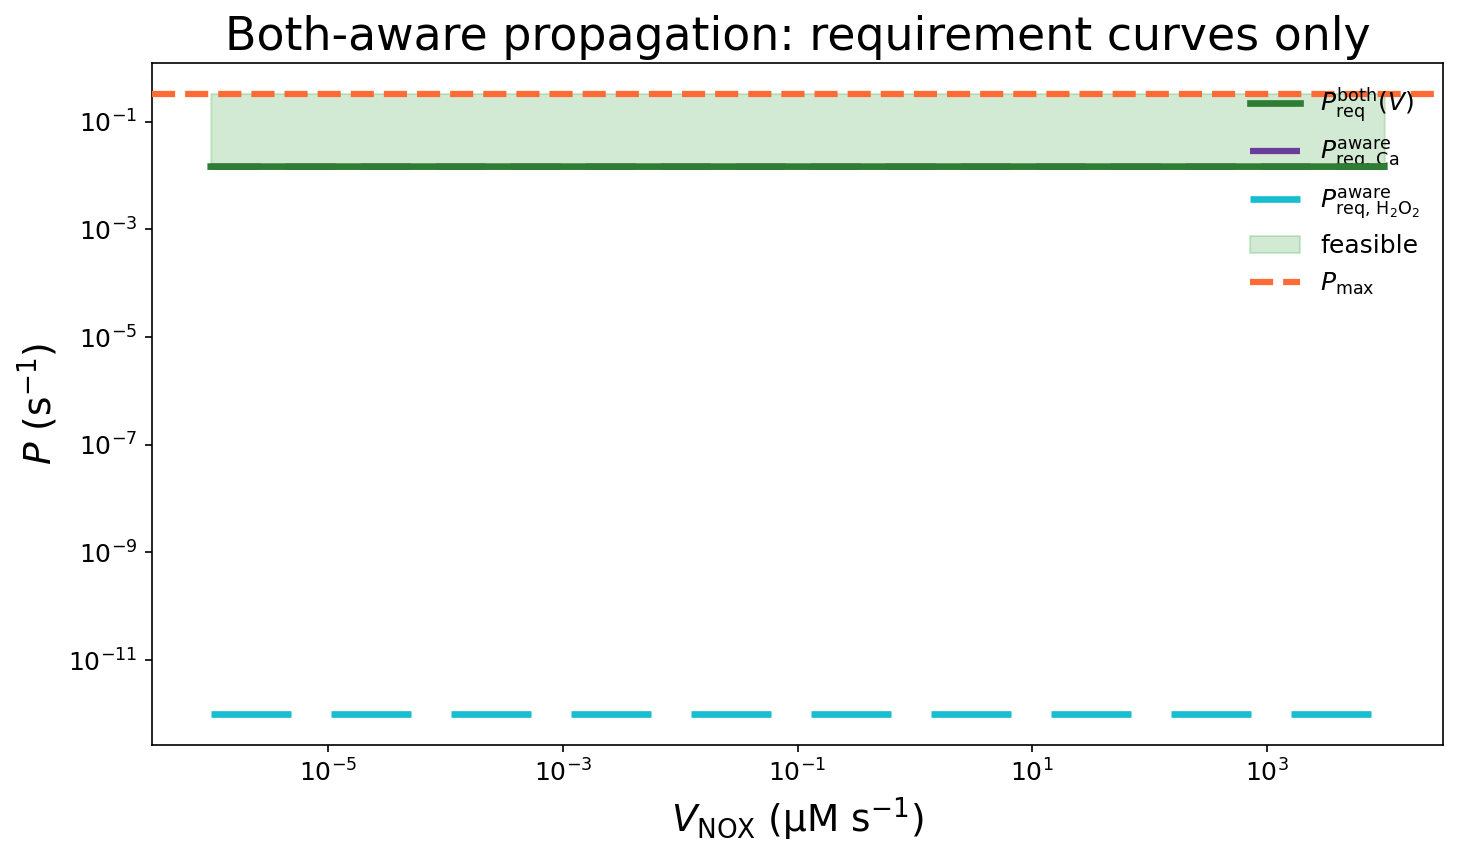

In [158]:
# === Sensitivity bands (OP sweep) + optional bolus overlay ===
# Drop this AFTER your overlay figure cell. Run the ODE-producing cell first so sol/k/model_noref exist.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

# ----------------- knobs you can edit -----------------
C_range = (1e-8, 1e-5)        # Ca operating-point sweep [M]
H_range = (1e-10, 1e-3)       # H2O2 operating-point sweep [M]
nC, nH  = 25, 25              # grid resolution for the sweep
include_bolus   = True
H_bolus         = 1.2e-3      # 1.2 mM H2O2 bolus (instant post-bolus curve)
N_eff_used      = 1.0         # match your previous figure
Vloc_Ca_used    = 0.0         # local Ca source (if any)
V_grid_M_s      = np.geomspace(1e-12, 1e-2, 800)  # same V-grid (M/s)
# ------------------------------------------------------

# ---- helper: alias params if only params_h/params_ca exist ----
if "param_h" not in globals() and "params_h" in globals():
    param_h = params_h
if "param_c" not in globals() and "params_ca" in globals():
    param_c = params_ca

# ---- helpers + safe getters (work with your earlier param dicts) ----
def _get(d, *keys, default=None):
    for k in keys:
        if k in d: return float(d[k])
    return default

def _maybe(name, default):
    return float(globals().get(name, default))

def hill_slope(x, K, n):
    x = np.asarray(x, dtype=float)
    out = np.zeros_like(x)
    pos = x > 0
    if np.any(pos):
        Kn = K**n
        out[pos] = n * Kn * (x[pos]**(n-1)) / (Kn + x[pos]**n)**2
    return out if out.ndim else float(out)

def gamma_ca2nox(C):
    # d/dC [ Vmax*Hill(C;K_NOX, m_NOX) ]
    Km = K_NOX**m_NOX
    return Vmax_NOX * m_NOX * Km * (C**(m_NOX-1)) / (Km + C**m_NOX)**2

def S_IP3R_const():
    return hill_slope(np.array([IP3_0]), K_IP3, n_IP3)[0] * G_CICR

def alpha_eff(V_M_s, H0):
    # Ca gain per P: direct Ca + IP3 (const slope) + TRPM2(H_eff(V))
    H_eff = H0 + V_M_s/ max(kappa_H, 1e-30)
    S_TRPM2 = hill_slope(H_eff, K_TRPM2_H, n_TRPM2) * G_TRPM2
    return dCa_nb_perP + dIP3_nb_perP * S_IP3R_const() + dH_nb_forCa * S_TRPM2

def P_req_H2O2_caaware(V_M_s, C_op, H0):
    # H2O2-aware requirement with Ca→NOX back-coupling
    numer = np.maximum(kappa_H*dH_act - V_M_s, 0.0)
    denom = N_eff_used*dH_nb + gamma_ca2nox(C_op) * alpha_eff(V_M_s, H0)
    return np.maximum(numer/np.maximum(denom, 1e-30), 1e-12)

def P_req_Ca(V_M_s, H0):
    # not Ca-aware (your Step-1 formula), but α depends on H via TRPM2
    a = alpha_eff(V_M_s, H0)
    numer = np.maximum(kappa_C*dC_act - Vloc_Ca_used, 0.0) - a*V_M_s
    return np.maximum(numer/np.maximum(N_eff_used*dC_nb, 1e-30), 1e-12)

# --- Aware requirements (scalar H0,C0 inputs; vector V) ---
def P_req_H2O2_aware(V_M_s, C_op, H0):
    """
    H2O2-aware: Ca at operating point C_op boosts NOX via gamma(C),
    and TRPM2/IP3R raise Ca gain that feeds back into H2O2 delivery.
    """
    V_M_s = np.asarray(V_M_s, dtype=float)
    numer = np.maximum(kappa_H*dH_act - V_M_s, 0.0)
    denom = N_eff_used*dH_nb + gamma_ca2nox(C_op) * alpha_eff(V_M_s, H0)
    return np.maximum(numer/np.maximum(denom, 1e-30), 1e-12)

def P_req_Ca_aware(V_M_s, H0):
    """
    Ca-aware: Ca requirement where the Ca gain α depends on H via TRPM2 (through H_eff(V)).
    """
    V_M_s = np.asarray(V_M_s, dtype=float)
    a = alpha_eff(V_M_s, H0)
    numer = np.maximum(kappa_C*dC_act - Vloc_Ca_used, 0.0) - a*V_M_s
    return np.maximum(numer/np.maximum(N_eff_used*dC_nb, 1e-30), 1e-12)

def P_req_both(V_M_s, H0, C0):
    """Both-aware envelope: max of the two aware requirements."""
    P_H = P_req_H2O2_aware(V_M_s, C0, H0)
    P_C = P_req_Ca_aware(V_M_s, H0)
    return np.maximum(P_H, P_C), P_H, P_C

def overlay_bothaware_time_snapshots(ax=None, V_grid_M_s=None, times=None, num=8,
                                     legend_label="time snapshots (ODE)"):
    """
    Draw time-colored P_req_both(V) curves using operating-point snapshots (H0(t), C0(t))
    taken from the ODE solution 'sol'. Keeps kinetic constants fixed, varies only H0 and C0.
    Adds a proxy handle so the bundle appears in the legend.
    """
    # required globals (provided by your both-aware heatmap cell / model)
    required = ("sol","param_h","param_c","alpha_eff","gamma_ca2nox",
                "kappa_H","dH_act","dH_nb","N_eff_used")
    missing = [name for name in required if name not in globals()]
    if missing:
        print("Time-snapshot overlay skipped — missing:", ", ".join(missing))
        return

    global sol, alpha_eff, gamma_ca2nox, kappa_H, dH_act, dH_nb, N_eff_used

    ax = ax or plt.gca()
    V = V_grid_M_s if V_grid_M_s is not None else np.geomspace(1e-12, 1e-2, 600)

    # choose time points
    t_all = np.asarray(sol.t)
    if times is None:
        idx = np.linspace(0, len(t_all)-1, num).astype(int)
    else:
        times = np.atleast_1d(times).astype(float)
        idx = np.array([int(np.argmin(np.abs(t_all - tt))) for tt in times])
    t_sel = t_all[idx]

    # operating points from solution
    H0 = sol.y[1,  idx]   # H2O2
    C0 = sol.y[29, idx]   # Ca

    # colormap by time + proxy for legend
    norm = Normalize(vmin=t_sel.min(), vmax=t_sel.max())
    cmap = plt.cm.viridis
    proxy = Line2D([0],[0], color=cmap(norm(t_sel[-1])), lw=2.0, label=legend_label)

    # plot curves
    for tt, Ht, Ct in zip(t_sel, H0, C0):
        numer = np.maximum(kappa_H * dH_act - V, 0.0)
        denom = N_eff_used * dH_nb + gamma_ca2nox(Ct) * alpha_eff(V, Ht)
        P_req_both = np.maximum(numer / np.maximum(denom, 1e-30), 1e-12)
        ax.plot(V*1e6, P_req_both, lw=1.4, color=cmap(norm(tt)), alpha=0.95)

    # add proxy handle to legend (keeps one clean entry)
    handles, labels = ax.get_legend_handles_labels()
    if legend_label not in labels:
        handles.append(proxy); labels.append(legend_label)
        ax.legend(handles, labels, frameon=False, loc="best")

    # colorbar keyed to time
    sm = ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
    cb = plt.colorbar(sm, ax=ax, pad=0.02)
    cb.set_label("time (s)")
    
# ----------------- knobs you can edit -----------------
N_eff_used      = 1.0        # effective number of upstream neighbors
Vloc_Ca_used    = 0.0        # local Ca source not via GJ (ATP/P2Y etc.), M/s
V_grid_M_s      = np.geomspace(1e-12, 1e-2, 800)  # NOX drive (M/s)
P_grid_s     = np.geomspace(1e-6, 3e0, 500)       # y: coupling (s^-1)  <<< DEFINED HERE
Pmax_const   = float(globals().get("Pmax_const", 2.0e-1))
# ------------------------------------------------------

# Try to pull your parameter dicts
ph = globals().get("param_h")  or globals().get("params_h")  or {}
pc = globals().get("param_c")  or globals().get("params_ca") or {}

# H2O2 side
kappa_H   = _get(ph, "kappa_H", default=1e-2)          # s^-1
dH_act    = _get(ph, "dH_act", "dH_act_M", default=1e-7)
dH_nb     = _get(ph, "dH_nb",  "dH_nb_M",  default=1e-9)

# Ca side (for Ca requirement and Ca→NOX feedback)
kappa_C   = _get(pc, "kappa_C", default=1e-4)          # s^-1
dC_act    = _get(pc, "dC_act", "dC_act_M", default=6e-7)
dC_nb     = _get(pc, "dC_nb",  "dC_nb_M",  default=1.7e-6)
alpha0    = _get(pc, "alpha",  "alpha_gain", default=5.36e-9)  # baseline seconds (used only if needed)

# GJ payloads (per unit P_GJ)
dCa_nb_perP  = float(pc.get("dCa_nb_M_perP", 0.0))
dIP3_nb_perP = float(pc.get("dIP3_nb_M_perP", 1e-8))
dH_nb_forCa  = float(pc.get("dH_nb_M_perP",  dH_nb))  # reuse ΔH_v+1 if not provided

# TRPM2 / IP3R (use your globals if present)
K_TRPM2_H = _maybe("K_TRPM2_H_M", 1e-6)
n_TRPM2   = _maybe("n_TRPM2",     2.0)
G_TRPM2   = _maybe("G_TRPM2_M",   2e-7)      # Ca influx per TRPM2 slope

K_IP3     = _maybe("K_IP3_M",     3e-7)
n_IP3     = _maybe("n_IP3",       2.0)
IP3_0     = _maybe("IP3_0_M",     5e-8)
G_CICR    = _maybe("G_CICR_M",    5e-7)

# NOX Ca gate (for Ca→NOX feedback into H2O2 requirement)
K_NOX     = float(globals().get("K_Ca_NOX5", 3e-7))
m_NOX     = float(globals().get("m_NOX5",    2.0))
Vmax_NOX  = float(pc.get("Vmax_NOX", 1e-3))  # M/s (cap on NOX Ca-gated production)

# Baseline operating point (if you saved H0/C0; otherwise small defaults)
H0_baseline = float(globals().get("H0_M", 1e-9))
C0_baseline = float(globals().get("C0_M", 1e-7))

# ---- build bands by sweeping operating points ----
C_vals = np.geomspace(*C_range, nC)
H_vals = np.geomspace(*H_range, nH)
V      = V_grid_M_s

# Vectorized grids: (nH,1,1) x (1,nC,1) x (1,1,nV)
H0g = H_vals[:,None,None]
Cg  = C_vals[None,:,None]
Vg  = V[None,None,:]

# H2O2-aware band
alpha_g = alpha_eff(Vg, H0g)              # (nH,1,nV)
gamma_g = gamma_ca2nox(Cg)                # (1,nC,1)
denom_g = N_eff_used*dH_nb + gamma_g*alpha_g
numer_g = np.maximum(kappa_H*dH_act - Vg, 0.0)
P_H2 = np.maximum(numer_g/np.maximum(denom_g,1e-30), 1e-12)
P_H2_min = P_H2.min(axis=(0,1))
P_H2_max = P_H2.max(axis=(0,1))

# Ca band (vary H only; C_op doesn’t change Ca requirement directly)
alpha_h = alpha_eff(Vg, H0g)              # (nH,1,nV)
numer_c = np.maximum(kappa_C*dC_act - Vloc_Ca_used, 0.0) - alpha_h*Vg
P_Ca = np.maximum(numer_c/np.maximum(N_eff_used*dC_nb,1e-30), 1e-12)
P_Ca_min = P_Ca.min(axis=0)[0]
P_Ca_max = P_Ca.max(axis=0)[0]

# Midlines at the geometric centers of the OP ranges
H_mid = np.sqrt(H_range[0]*H_range[1])
C_mid = np.sqrt(C_range[0]*C_range[1])
P_H2_mid = P_req_H2O2_caaware(V, C_mid, H_mid)
P_Ca_mid = P_req_Ca(V, H_mid)

# Optional: instant post-bolus midline (increase baseline H0 by ΔH)
if include_bolus:
    H_post = H_mid + H_bolus
    P_H2_bolus = P_req_H2O2_caaware(V, C_mid, H_post)
    P_Ca_bolus = P_req_Ca(V, H_post)

# 1) Build the curves on your V-grid using the baseline OP (H0_baseline, C0_baseline)
V = V_grid_M_s
V_uM_s = V * 1e6

P_both_curve, P_h_curve, P_c_curve = P_req_both(V, H0_baseline, C0_baseline)
P_ca_aw_curve  = P_req_Ca_aware(V, H0_baseline)
P_h2_aw_curve  = P_req_H2O2_aware(V, C0_baseline, H0_baseline)

# Use a local curve with matching length for shading
P_curve = P_both_curve

# 2) Plot
fig, ax = plt.subplots(figsize=(10, 6))

# both-aware (green solid)
ax.loglog(V_uM_s, P_both_curve, color="#2e7d32", lw=3.2,
          label=r"$P_{\rm req}^{\rm both}(V)$", zorder=6)

# Ca-aware (purple, medium dash)
ax.loglog(V_uM_s, P_ca_aw_curve, color="#6a3d9a", lw=3, ls=(0, (8, 4)),
          label=r"$P_{\rm req,\,Ca}^{\rm aware}$", zorder=5)

# H2O2-aware (teal, long dash, with white halo for contrast vs purple)
h2, = ax.loglog(V_uM_s, P_h2_aw_curve, color="#17becf", lw=3.2, ls=(0, (12, 6)),
                label=r"$P_{\rm req,\,H_2O_2}^{\rm aware}$", zorder=7)

feas = P_curve <= Pmax_const
feas_poly = ax.fill_between(
    V_uM_s, P_curve, np.full_like(P_curve, Pmax_const), where=feas,
    color="#4CAF50", alpha=0.25, interpolate=True, label="feasible"
)

ax.axhline(Pmax_const, color="#FF6B35", lw=3, ls="--", label=r"$P_{\max}$", zorder=4)

import matplotlib.patheffects as pe
h2.set_path_effects([pe.Stroke(linewidth=5.2, foreground="white", alpha=0.55), pe.Normal()])

# axes cosmetics
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$V_{\rm NOX}$ (µM s$^{-1}$)")
ax.set_ylabel(r"$P$ (s$^{-1}$)")
ax.xaxis.set_major_locator(LogLocator(base=10)); ax.yaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_major_formatter(LogFormatterMathtext()); ax.yaxis.set_major_formatter(LogFormatterMathtext())
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
ax.xaxis.set_minor_formatter(NullFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_title("Both-aware propagation: requirement curves only")

# Optional: overlay ODE time snapshots, if your helper & ODE objects exist
if "overlay_time_snapshots_on_current_axes" in globals():
    overlay_time_snapshots_on_current_axes(
        times=[0, 5, 10, 60, 300, 600],
        N_eff=N_eff_used, Vloc_Ca_Ms=Vloc_Ca_used
    )
    # add proxy legend entry for snapshots
    proxy = Line2D([], [], color="k", lw=3, alpha=0.5)
    handles, labels = ax.get_legend_handles_labels()
    handles += [proxy]
    #labels += ["ODE snapshots"]
    ax.legend(handles, labels, frameon=False, loc="upper right")
else:
    ax.legend(frameon=False, loc="upper right")

plt.tight_layout()
plt.show()

/var/folders/b8/kf34269923s23y5356xntqnr0000gn/T/ipykernel_94334/231927966.py:218: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


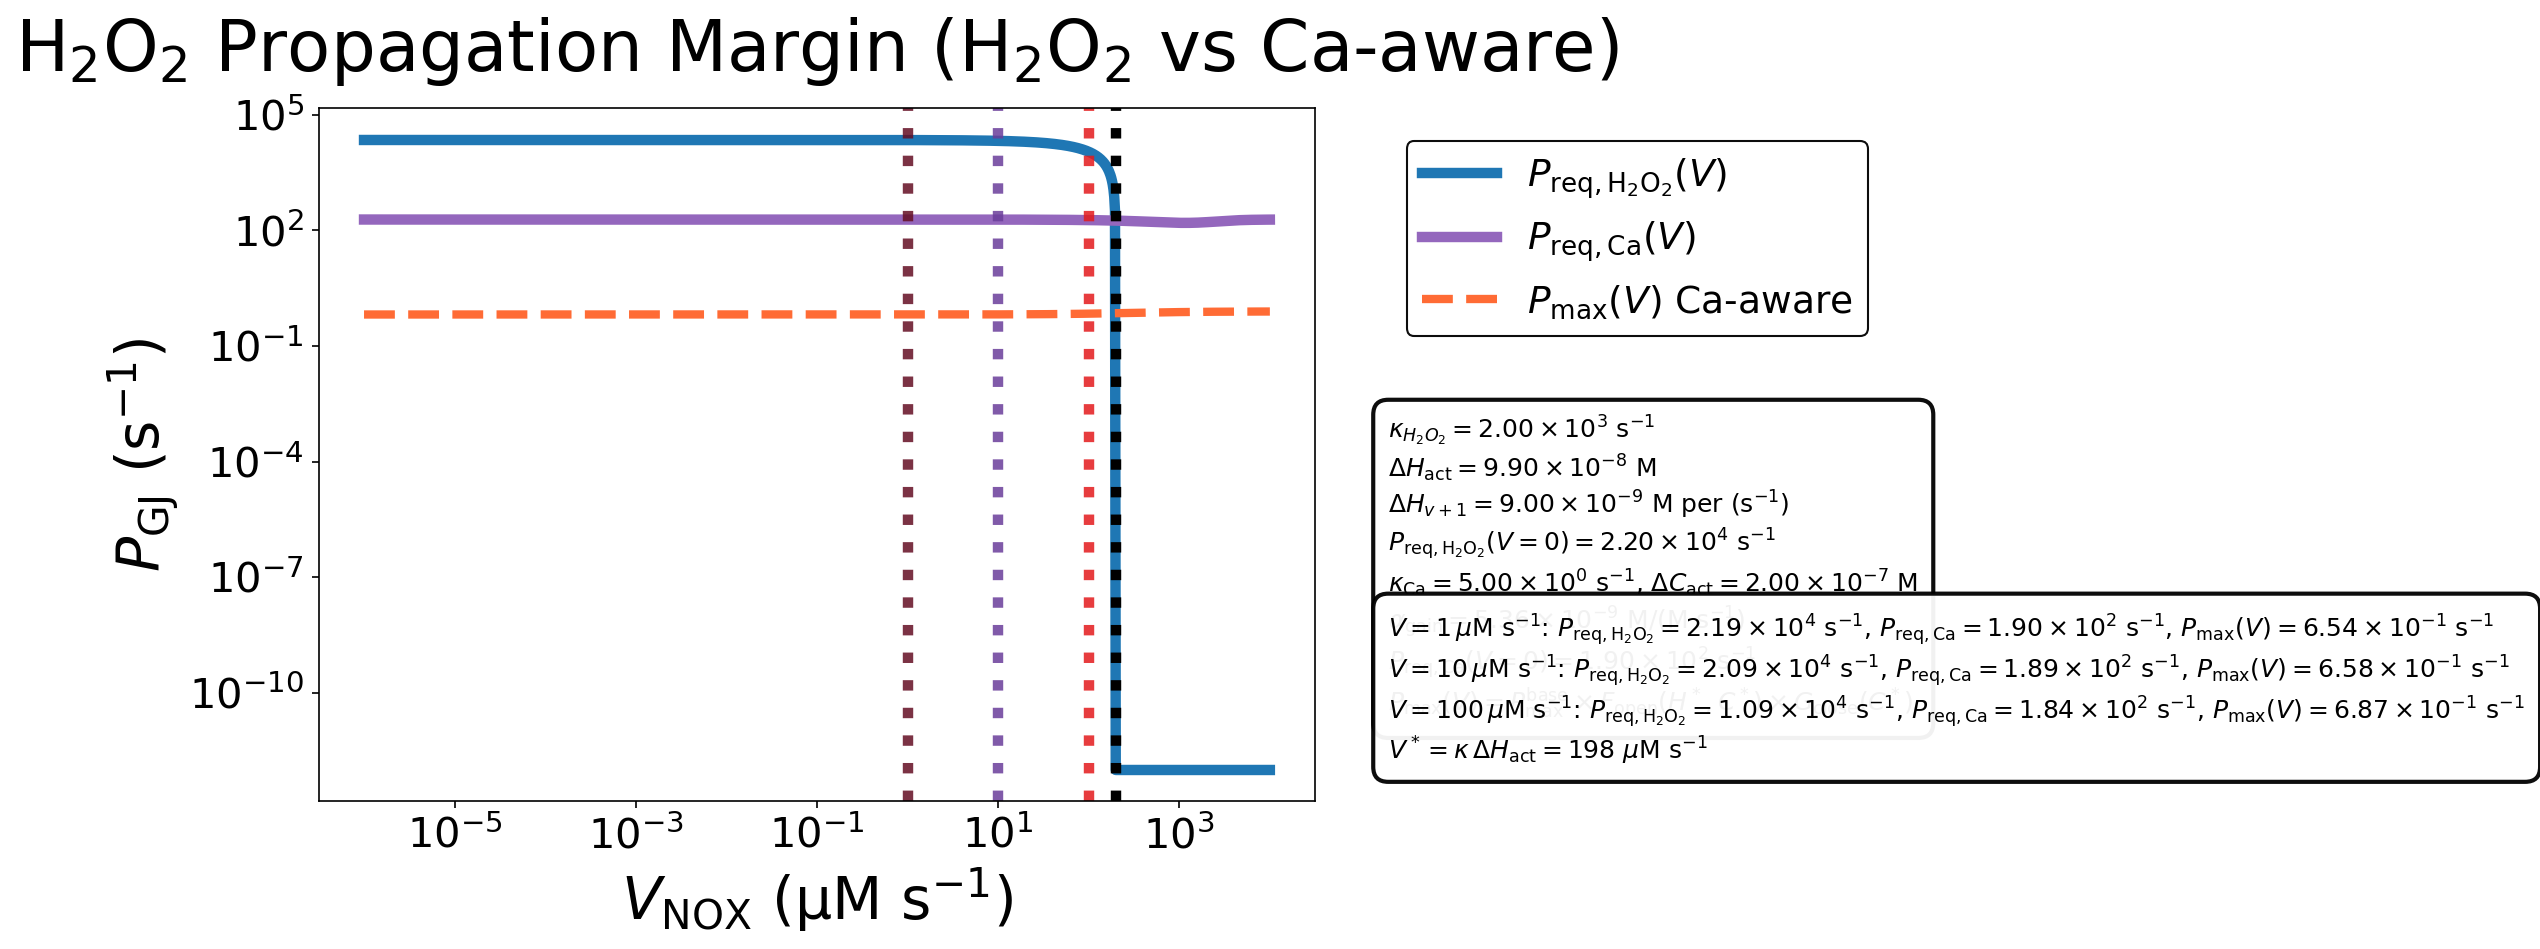

In [159]:
# === H2O2 propagation margin (H2O2 vs Ca-aware) — right sidebar, Ca-aware Pmax ===
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

# ---------- Baseline numbers ----------
# H2O2-side (receiver compartment)
kappa      = 2.00e3      # s^-1  (effective H2O2 clearance)
dH_act_M   = 9.90e-8     # M     (H2O2 increment to reach Ca trigger if H2O2-only)
dH_nb_M    = 9.00e-9     # M     (neighbor H2O2 difference per unit GJ P) == ΔH_{v+1}
Pmax_const = 2.14e-1     # s^-1  (baseline pore-physics ceiling at rest)

# Ca-side (receiver compartment)
kappa_Ca   = 5.0         # s^-1  (effective Ca clearance)
dCa_act_M  = 2.0e-7      # M     (Ca increment to trigger)
Vloc_Ca_Ms = 0.0         # M/s   (local Ca influx/release not tied to GJs)

# GJ-delivered messengers (per unit P_GJ, units M per (s^-1))
dCa_nb_M_perP  = 0.0     # direct Ca via GJ (often small)
dIP3_nb_M_perP = 1.0e-8  # IP3 via GJ per unit P_GJ
dH_nb_M_perP   = dH_nb_M # H2O2 via GJ per unit P_GJ (match ΔH_{v+1})

# IP3R (CICR) gating (for sensitivity of IP3R)
K_IP3_M   = 3.0e-7
n_IP3     = 2.0
IP3_0_M   = 5.0e-8
G_CICR_M  = 5.0e-7       # Ca released for unit change of IP3R open prob.

# TRPM2 (H2O2-sensitive) gating (for sensitivity of TRPM2)
K_TRPM2_H_M = 1.0e-6
n_TRPM2     = 2.0
H0_M        = 0.0
G_TRPM2_M   = 2.0e-7     # Ca influx for unit change of TRPM2 open prob.

# Optional paracrine ATP (local, not GJ-limited)
J_ATP_Ms = 0.0
S_P2Y    = 0.0

# --- Ca-aware GJ opening/closure parameters (used for Pmax(V)) ---
F_max   = 10.0           # hard cap on total fold-opening
rho_H   = 3.0            # extra fold from H2O2 (1 = none)
K_GJ_H  = 50e-9          # half-activation by H2O2
rho_C   = 3.0            # extra fold from Ca2+ (1 = none)
K_GJ_C  = 300e-9         # half-activation by Ca2+
K_close = 1e-6           # Ca-dependent closure half
n_close = 2.0            # Hill for closure

# Map NOX drive -> Ca elevation used inside Pmax(V)
alpha_gain = 5.36e-9     # M per (M s^-1)  (ΔC ≈ alpha_gain * V)
C0_M       = 1.0e-7      # resting cytosolic Ca (for Pmax(V) context)

# NOX reference markers (vertical dotted lines)
Vrefs_uM_s = [1.0, 10.0, 100.0]

# ---------- Helpers ----------
def tex_sci(x, sig=3):
    if x == 0: return "0"
    e = int(np.floor(np.log10(abs(x))))
    m = x / 10**e
    return rf"{m:.{sig-1}f}\times 10^{{{e}}}"

def hill_slope(x, K, n):
    """Derivative of Hill(x)=x^n/(K^n+x^n) wrt x. Accepts scalar/array."""
    x = np.asarray(x, float)
    out = np.zeros_like(x)
    pos = x > 0
    if np.any(pos):
        Kn = K**n
        out[pos] = n * Kn * (x[pos]**(n-1)) / (Kn + x[pos]**n)**2
    return out if out.ndim else float(out)

def P_req_H2O2(V_M_s, kappa, dH_act_M, dH_nb_M):
    """H2O2-only requirement."""
    return np.maximum((kappa * dH_act_M - V_M_s) / max(dH_nb_M, 1e-30), 1e-12)

def P_req_Ca(V_M_s):
    """
    Ca-aware required GJ P (s^-1):
    combines Ca via GJ, IP3 via GJ -> CICR, and H2O2 via GJ -> TRPM2.
    V_M_s: NOX production (M/s) in receiver (affects local H2O2 excess H_eff = V/kappa).
    """
    V_M_s = np.asarray(V_M_s, float)
    H_eff_M = H0_M + V_M_s / max(kappa, 1e-30)           # local H2O2 ~ V/κ
    S_IP3R  = hill_slope(IP3_0_M, K_IP3_M, n_IP3) * G_CICR_M
    S_TRPM2 = hill_slope(H_eff_M, K_TRPM2_H_M, n_TRPM2) * G_TRPM2_M

    alpha_eff = dCa_nb_M_perP + dIP3_nb_M_perP * S_IP3R + dH_nb_M_perP * S_TRPM2
    rhs_local = Vloc_Ca_Ms + J_ATP_Ms * S_P2Y

    numer = np.maximum(kappa_Ca * dCa_act_M - rhs_local, 0.0)   # M/s
    denom = np.maximum(alpha_eff, 1e-30)                        # M per (s^-1)
    return np.maximum(numer / denom, 1e-12)                     # s^-1

def Pmax_ca_aware(V_M_s):
    """
    Ca-aware (V-dependent) ceiling for GJ coupling:
      Pmax_eff(V) = Pmax_const * F_open(H*,C*) * G_close(C*),
    with H* = H0 + ΔH_act + (1/κ)·V, C* = C0 + ΔC_act + α·V.
    """
    V_M_s = np.asarray(V_M_s, float)
    beta_H = 1.0 / max(kappa, 1e-30)            # ΔH ≈ beta_H * V
    Hs = H0_M + dH_act_M + beta_H * V_M_s
    Cs = C0_M + dCa_act_M + alpha_gain * V_M_s

    fH = Hs / (K_GJ_H + Hs)
    fC = Cs / (K_GJ_C + Cs)
    F_open = 1.0 + (rho_H - 1.0) * fH + (rho_C - 1.0) * fC
    F_open = np.minimum(F_open, F_max)

    G_cl = 1.0 / (1.0 + (Cs / K_close) ** n_close)

    return Pmax_const * F_open * G_cl

# ---------- Curves ----------
V_M_s  = np.geomspace(1e-12, 1e-2, 1200)  # M s^-1
V_uM_s = V_M_s * 1e6

P_curve_H    = P_req_H2O2(V_M_s, kappa, dH_act_M, dH_nb_M)
P_curve_C    = P_req_Ca(V_M_s)
Pmax_eff_V   = Pmax_ca_aware(V_M_s)       # <-- Ca-aware ceiling

V_star    = kappa * dH_act_M
V_star_uM = V_star * 1e6
P0_H      = P_req_H2O2(0.0, kappa, dH_act_M, dH_nb_M)
P0_C      = P_req_Ca(0.0)

# ---------- Figure with right sidebar ----------
plt.rcParams.update({
    "font.size": 18, "axes.titlesize": 34, "axes.labelsize": 28,
    "xtick.labelsize": 20, "ytick.labelsize": 20, "legend.fontsize": 18
})

fig = plt.figure(figsize=(12, 6))
gs  = GridSpec(nrows=1, ncols=2, width_ratios=[4.2, 1.4], wspace=0.10, figure=fig)
ax  = fig.add_subplot(gs[0, 0])  # main plot
axr = fig.add_subplot(gs[0, 1])  # right sidebar
axr.axis('off')

# --- main plot ---
colors = ["#640E23", "#6a3d9a", "#e31a1c"]

line_H, = ax.loglog(V_uM_s, P_curve_H, lw=5, color="#1f77b4",
                    label=r"$P_{\rm req,H_2O_2}(V)$")
line_C, = ax.loglog(V_uM_s, P_curve_C, lw=5, color="#9467bd",
                    label=r"$P_{\rm req,Ca}(V)$")
line_PM, = ax.loglog(V_uM_s, Pmax_eff_V, color="#FF6B35", lw=4, ls="--",
                     label=r"$P_{\max}(V)$ Ca-aware")

for i, Vref_uM in enumerate(Vrefs_uM_s):
    ax.axvline(Vref_uM, color=colors[i % len(colors)], ls=":", lw=5, alpha=0.85)
ax.axvline(V_star_uM, color="k", lw=5, ls=":")

# feasible region w.r.t. Ca-aware ceiling
feas = P_curve_C <= Pmax_eff_V
ax.fill_between(V_uM_s, P_curve_C, Pmax_eff_V, where=feas,
                color="#4CAF50", alpha=0.25, interpolate=True,
                label="feasible (Ca-aware)")

# cosmetics
ax.set_title("H$_2$O$_2$ Propagation Margin (H$_2$O$_2$ vs Ca-aware)", pad=18)
ax.set_xlabel(r"$V_{\rm NOX}$ (µM s$^{-1}$)")
ax.set_ylabel(r"$P_{\rm GJ}$ (s$^{-1}$)")
ax.set_xscale('log'); ax.set_yscale('log')
ax.xaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_major_formatter(LogFormatterMathtext())
ax.yaxis.set_major_formatter(LogFormatterMathtext())
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10)*0.1))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())

# --- RIGHT SIDEBAR (all boxes) ---
# 1) Legend box (top)
handles = [line_H, line_C, line_PM]
labels  = [h.get_label() for h in handles]
leg = axr.legend(handles, labels, loc='upper left', frameon=True, fancybox=True,
                 framealpha=0.95, edgecolor="black",
                 bbox_to_anchor=(0.02, 0.98), bbox_transform=axr.transAxes)
leg.get_frame().set_facecolor("white")

# 2) Parameter box (middle)
param_text = (
    fr"$\kappa_{{H_2O_2}}={tex_sci(kappa)}$ s$^{{-1}}$" + "\n" +
    fr"$\Delta H_{{\rm act}}={tex_sci(dH_act_M)}$ M" + "\n" +
    fr"$\Delta H_{{v+1}}={tex_sci(dH_nb_M)}$ M per (s$^{{-1}}$)" + "\n" +
    fr"$P_{{\rm req,H_2O_2}}(V=0)={tex_sci(P0_H)}$ s$^{{-1}}$" + "\n" +
    fr"$\kappa_{{\rm Ca}}={tex_sci(kappa_Ca)}$ s$^{{-1}}$, "
    fr"$\Delta C_{{\rm act}}={tex_sci(dCa_act_M)}$ M" + "\n" +
    fr"$\alpha_{{\rm gain}}={tex_sci(alpha_gain)}$ M/(M s$^{{-1}}$)" + "\n" +
    fr"$P_{{\rm req,Ca}}(V=0)={tex_sci(P0_C)}$ s$^{{-1}}$" + "\n" +
    r"$P_{\max}(V)=P_{\max}^{\rm base}\times F_{\rm open}(H^*,C^*)\times G_{\rm close}(C^*)$"
)
axr.text(0.02, 0.56, param_text, transform=axr.transAxes, va='top', ha='left',
         fontsize=12, bbox=dict(boxstyle="round,pad=0.6", fc="white",
         ec="black", lw=2, alpha=0.95), clip_on=False)

# 3) V-ref summary box (bottom)
vref_lines = []
for Vref_uM in Vrefs_uM_s:
    Vref_M = Vref_uM * 1e-6
    PrefH  = P_req_H2O2(Vref_M, kappa, dH_act_M, dH_nb_M)
    PrefC  = P_req_Ca(Vref_M)
    PmaxV  = float(Pmax_ca_aware(Vref_M))
    vref_lines.append(
        fr"$V={Vref_uM:g}\,\mu$M s$^{{-1}}$: "
        fr"$P_{{\rm req,H_2O_2}}={tex_sci(PrefH)}$ s$^{{-1}}$, "
        fr"$P_{{\rm req,Ca}}={tex_sci(PrefC)}$ s$^{{-1}}$, "
        fr"$P_{{\max}}(V)={tex_sci(PmaxV)}$ s$^{{-1}}$"
    )
vref_lines.append(rf"$V^*=\kappa\,\Delta H_{{\rm act}}={V_star_uM:.3g}\ \mu\mathrm{{M}}\ \mathrm{{s}}^{{-1}}$")
axr.text(0.02, 0.05, "\n".join(vref_lines), transform=axr.transAxes,
         va='bottom', ha='left', fontsize=12,
         bbox=dict(boxstyle="round,pad=0.6", fc="white",
                   ec="black", lw=2, alpha=0.95), clip_on=False)

plt.tight_layout()
plt.show()


In [160]:
# ...existing code...
# Plot overlay vs model (uses existing obs if available)
import matplotlib.pyplot as plt
import matplotlib as mpl
import re
def _short_label(lbl: str) -> str:
    m = re.search(r'Cell\s*\d+', lbl)
    return m.group(0) if m else lbl.split(':')[-1].strip()

# Nicely formatted side-by-side plots: raw and cumulative
if tracks:
    # Precompute sorted tracks and bounds
    tracks_sorted = []
    t_min, t_max = None, None
    y_min, y_max = None, None
    for tr in tracks:
        tr_s = tr.sort_values("time_s").copy()
        tr_s["H2O2_M"] = pd.to_numeric(tr_s["H2O2_M"], errors="coerce")
        tr_s.dropna(subset=["time_s", "H2O2_M"], inplace=True)
        if tr_s.empty:
            continue
        tracks_sorted.append(tr_s)
        t_min = tr_s["time_s"].min() if t_min is None else min(t_min, tr_s["time_s"].min())
        t_max = tr_s["time_s"].max() if t_max is None else max(t_max, tr_s["time_s"].max())
        pos = tr_s["H2O2_M"][tr_s["H2O2_M"] > 0]
        if not pos.empty:
            y_min = pos.min() if y_min is None else min(y_min, pos.min())
            y_max = pos.max() if y_max is None else max(y_max, pos.max())

    n = len(tracks_sorted)
    colors = plt.cm.tab20(np.linspace(0, 1, max(3, min(20, n))))

    with mpl.rc_context({
        "font.size": 10, "axes.titlesize": 12, "axes.labelsize": 11,
        "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
        "figure.dpi": 150, "savefig.dpi": 150
    }):
        fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"wspace": 0.28}, sharex=True)
        ax_raw, ax_cum = axs

        max_legend = 12
        for i, tr_s in enumerate(tracks_sorted):
            col = colors[i % len(colors)]
            lbl = _short_label(tr_s["label"].iloc[0]) if n <= max_legend else None
            y = tr_s["H2O2_M"].clip(lower=1e-12)  # avoid log(0)
            # raw
            ax_raw.plot(tr_s["time_s"], y, lw=2, alpha=0.95, color=col, label=lbl)
            # cumulative (discrete sum, as requested)
            ycum = tr_s["H2O2_M"].fillna(0).cumsum()
            ax_cum.plot(tr_s["time_s"], ycum, lw=2, alpha=0.95, color=col)

        # Raw axis formatting
        ax_raw.set_title("Experimental H2O2 tracks")
        ax_raw.set_yscale("log")
        ax_raw.set_xlabel("Time (s)")
        ax_raw.set_ylabel("H2O2 (M)")
        if y_min is not None and y_max is not None:
            ax_raw.set_ylim(max(y_min*0.8, 1e-12), y_max*1.2)
        if t_min is not None and t_max is not None:
            ax_raw.set_xlim(left=max(0, t_min), right=t_max)

        # Cumulative axis formatting
        ax_cum.set_title("Cumulative sum (Σ up to t)")
        ax_cum.set_xlabel("Time (s)")
        ax_cum.set_ylabel("Cumulative H2O2 (M)")
        if t_min is not None and t_max is not None:
            ax_cum.set_xlim(left=max(0, t_min), right=t_max)

        # Light grid and clean spines
        for ax in axs:
            ax.grid(True, which="both", ls=":", alpha=0.35)
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)

        # Shared legend (only if not too many tracks)
        if n and n <= max_legend:
            handles, labels = ax_raw.get_legend_handles_labels()
            fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
            plt.tight_layout(rect=[0, 0, 0.86, 1.0])
        else:
            plt.tight_layout()

        plt.show()
def plot_cumulative_tracks_poster(tracks, method="sum"):
    """
    Standalone cumulative-sum figure for experimental H2O2 tracks.
    method: "sum" (discrete cumsum, default) or "integral" (time-weighted trapezoid).
    """
    import numpy as np
    import pandas as pd
    import re
    import matplotlib.pyplot as plt
    import matplotlib as mpl

    if not tracks:
        return

    # Clean/sort tracks
    tracks_sorted, t_min, t_max = [], None, None
    for tr in tracks:
        tr_s = tr.sort_values("time_s").copy()
        tr_s["H2O2_M"] = pd.to_numeric(tr_s["H2O2_M"], errors="coerce")
        tr_s.dropna(subset=["time_s", "H2O2_M"], inplace=True)
        if tr_s.empty:
            continue
        tracks_sorted.append(tr_s)
        t_min = tr_s["time_s"].min() if t_min is None else min(t_min, tr_s["time_s"].min())
        t_max = tr_s["time_s"].max() if t_max is None else max(t_max, tr_s["time_s"].max())

    # Order curves by earliest rise (leftmost first)
    def first_rise_time(tr_s, thr=1e-11):
        y = tr_s["H2O2_M"].to_numpy()
        t = tr_s["time_s"].to_numpy()
        idx = np.argmax(y > thr)
        return t[idx] if np.any(y > thr) else t[0]
    tracks_sorted = sorted(tracks_sorted, key=lambda tr: first_rise_time(tr))

    n = len(tracks_sorted)
    if n == 0:
        return

    # Purple, green, red (repeat if >3 curves)
    base_colors = ["#6a3d9a", "#2ca02c", "#e31a1c"]
    colors = [base_colors[i % len(base_colors)] for i in range(n)]

    # Poster typography (matches your other figure)
    with mpl.rc_context({
        "font.size": 18, "axes.titlesize": 34, "axes.labelsize": 28,
        "xtick.labelsize": 20, "ytick.labelsize": 20, "legend.fontsize": 20,
        "figure.dpi": 150, "savefig.dpi": 150
    }):
        fig, ax = plt.subplots(figsize=(15, 7.5))

        for i, tr_s in enumerate(tracks_sorted):
            col = colors[i]
            # label like "Cell N" if present
            lbl = None
            if "label" in tr_s:
                m = re.search(r"Cell\s*\d+", str(tr_s["label"].iloc[0]))
                lbl = m.group(0) if m else str(tr_s["label"].iloc[0])
            if not lbl:
                lbl = f"Cell {i+1}"

            if method == "integral":
                t = tr_s["time_s"].to_numpy()
                y = tr_s["H2O2_M"].fillna(0).to_numpy()
                ycum = np.concatenate([[0], np.cumsum(0.5 * (y[1:] + y[:-1]) * (t[1:] - t[:-1]))])
                x = t
            else:
                ycum = tr_s["H2O2_M"].fillna(0).cumsum()
                x = tr_s["time_s"]

            ax.plot(x, ycum, lw=5, alpha=0.95, color=col, label=lbl)

        ax.set_title("Cumulative sum of simulated H2O2 tracks")
        ax.set_xlabel("Time (s)")
        ax.set_ylabel("Cumulative H2O2 (M)")
        if t_min is not None and t_max is not None:
            ax.set_xlim(left=max(0, t_min), right=t_max)

        ax.grid(True, which="both", ls=":", alpha=0.35)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Legend outside on the right
        leg = ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5),
                        frameon=True, fancybox=True, framealpha=0.95, edgecolor="black")
        leg.get_frame().set_facecolor("white")

        plt.tight_layout(rect=[0, 0, 0.82, 1.0])
        plt.show()
# Usage:
plot_cumulative_tracks_poster(tracks, method="sum")  # or method="integral"
# ...existing code...

NameError: name 'tracks' is not defined

toggle nox2 production rate for biphasic effect

In [ ]:
k = np.zeros(100)  # Defining the array, k, that will house reaction rates
        # Rxns (Cytosolic)

k[0] = 2e-2  # Permeability constant (plasma membrane) (cm/s)
k[1] = 1.1e-7  # Intracellular peroxide production (M/s)
k[2] = 2.1e7  # GPx_red reacting with H2O2in (M-1*s-1)
k[3] = 4e4  # GPx_ox reacting with GSH (M-1*s-1)
k[4] = 1e7  # GPx-SSG reacting with GSH (M-1*s-1)
k[5] = 3.4e7  # Catalase reacts with H2O2 inside peroxisome (M-1*s-1)
k[6] = 5.7e-5  # Km of NADP+ (M)
k[7] = 100e-6  # Peroxiredoxin is oxidized by H2O2 (M-1*s-1)
k[8] = 0.0049e-6  # Oxidized peroxiredoxin is over-oxidized by H2O2 (M-1*s-1)
k[9] = 3e-3  # Reduction of overoxidized Prx by Srx enzyme (s-1)
k[10] = 15  # Self-catalyzed disulfide formation of Prx-SS from Prx-SOH (s-1)
k[11] = 2.1e-6 # Peroxiredoxin is reduced by Thioredoxin (M-1*s-1)
k[12] = 7.4e-05  # Auto-oxidation of GSH (s-1)
k[13] = 1e4  # Protein monothiol oxidized by H2O2 (M-1*s-1)
k[14] = 1.2e5  # Oxidized Protein monothiol glutathionylated by GSH (M-1*s-1)
k[15] = 9.1e4  # Grx-SH de-glutathionylates Protein-SSG (M-1*s-1)
k[16] = 3.7e4  # GSH de-glutathionylates Grx-SSG (M-1*s-1)
k[17] = 5e5  # Protein dithiol oxidized by H2O2 (M-1*s-1)
k[18] = 1e5  # Protein disulfide reduced by Trx (M-1*s-1)
k[19] = 3.2e6  # GSSG reduced by GR (M-1*s-1)
k[20] = 2e7  # Oxidized Thioredoxin reduced by TrxR (M-1*s-1)
k[21] = 3.75e-04  # Production of NADPH by G6P-DH (M/s)
k[22] = 3e-3  # Permeability constant (peroxisomal membrane) (cm/s)
k[23] = 4.1e-7  # GSH synthesis (M/s)
k[24] = 1.2e-8  # GSSG efflux (M/s)
k[25] = 1.2e-7  # GSH + GSSG efflux (M/s)
k[26] = 7.45e-10  # Trx_SH efflux (M/s)
k[27] = 6.97e-10  # Trx_SH synthesis (M/s)
k[28] = 0#1e-5 # nox generation of superoxide ()    #Banfi B. et al, JBC 2002
k[29] = 0#4e9 # superoxide dismutase reduction and oxidation by superoxide (M-1*s-1), from Fee J.A. & Bull C. The journal of biological chemistry 1986
k[30] = 0 # intracellular superoxide production (M/s)
k[31] = 0 # nox h2o2 production (M/s)
k[32] = 1.765e-7 # nox 2 (M/s?)   # activates runaway at 1.8e-7
k[33] = 1e-7 # km nox2 (M) for activation by h2o2


# ---- new Ca2+ and NOX5 parameters (packed into k) ----
# ER Ca release via oxidized IP3R
k[34] = 1e-4    # V_rel (M/s) ER -> cyt max release
k[35] = 1e-7     # K_IP3R_H (M) H2O2 half-activation for IP3R oxidation and activation
k[36] = 4       # nH (Hill exponent H2O2→IP3R)
k[37] = 5e-7     # K_er (M) ER Ca activation for release

# SERCA uptake with H2O2 inhibition
k[38] = 2.5e-7     # V_SERCA (M/s)
k[39] = 1e-6     # K_ser (M) cyt Ca half-sat for SERCA uptake, # 10.1113/jphysiol.2013.269373
k[40] = 1e-6     # K_SERCA_H (M) H2O2 inhibition scale
k[41] = 2        # m_inhib (Hill for H2O2 inhibition)

# TRPM2 H2O2-gated influx
k[42] = 5e-5     # P_TRPM2 (1/s) effective permeability scale
k[43] = 5e-7     # K_TRPM2_H (M) H2O2 half-activation (~10–100 µM)
k[44] = 2.0        # p_TRPM2 (Hill exponent)

# SOCE (store-operated Ca entry) factor
k[45] = 1.5e-6     # P_SOCE (1/s)
k[46] = 100e-7     # K_store (M) ER Ca scale where SOCE ramps

k[47] = 2.1 # SERCA n (Hill exponent for Ca), 10.1113/jphysiol.2013.269373

# NOX5 Ca-dependent ROS production
k[48] = 5e-7    # Vmax_NOX5 (M/s)  (tune 1e-8 to 1e-7)
k[49] = 0.71e-6    # K_Ca (M) ~ 1 µM half-activation
k[50] = 4        # m_nox (Hill exponent for Ca)

k[51] = 5e-7     # K_IP3R_H_inh (M) H2O2 half-inhibition for IP3R oxidation
k[52] = 2       # mH_inh (Hill exponent H2O2 inhibition)
k[53] = 5e-6      # K_IP3R_C_inh (M) Ca half-inhibition for IP3R
k[54] = 2       # n_Ca_IP3R_act (Hill exponent Ca activation)

# ER capacity & overflow
k[55] = 1.1e-4     # C_ER_max [M]   (e.g., 0.5 mM; set well above baseline ~1e-4)
k[56] = 1e-1       # k_over  [1/s]  (how fast overflow evacuates when over cap)
k[57] = 5e-7    # K_IP3R_Ca (M) Cytosolic Ca scale for IP3R activation
# Cytosolic Ca extrusion (lumped PMCA/NCX)
k[58] = 1e-9        # 1/s  (cytosolic Ca leak rate constant)

# NOX5 NADPH Km (you already have Vmax & Ca gate)
k[62] = 1.4e-5                    # Km_NOX5_NADPH [M] (~14 µM)

# Duox1/2 (additional Ca-dependent ROS source)
k[63] = 1e-9                 # kcat_duox_low_Ca (s-1)  (tune 1e-8 to 1e-7)
k[64] = 0.87e-6                    # K_Duox_Ca (M) ~ 1 µM half-activation
k[65] = 4                           # m_duox (Hill exponent for Ca)
k[66] = 24.31e-6                    # Km_Duox_NADPH_low_Ca [M] (~14 µM)
k[67] = 11.52e-6                    # Km_Duox_NADPH_high_Ca [M] (~140 µM)

# TRPM2 Ca influx (you already have H2O2 gate) due to calcium
k[68] = 16.9e-6     # k_trpm2 ca (M) ca half-activation (~0.5 µM), doi.org/10.1073/pnas.0811725106
k[69] = 2                         # n (trpm2) ca

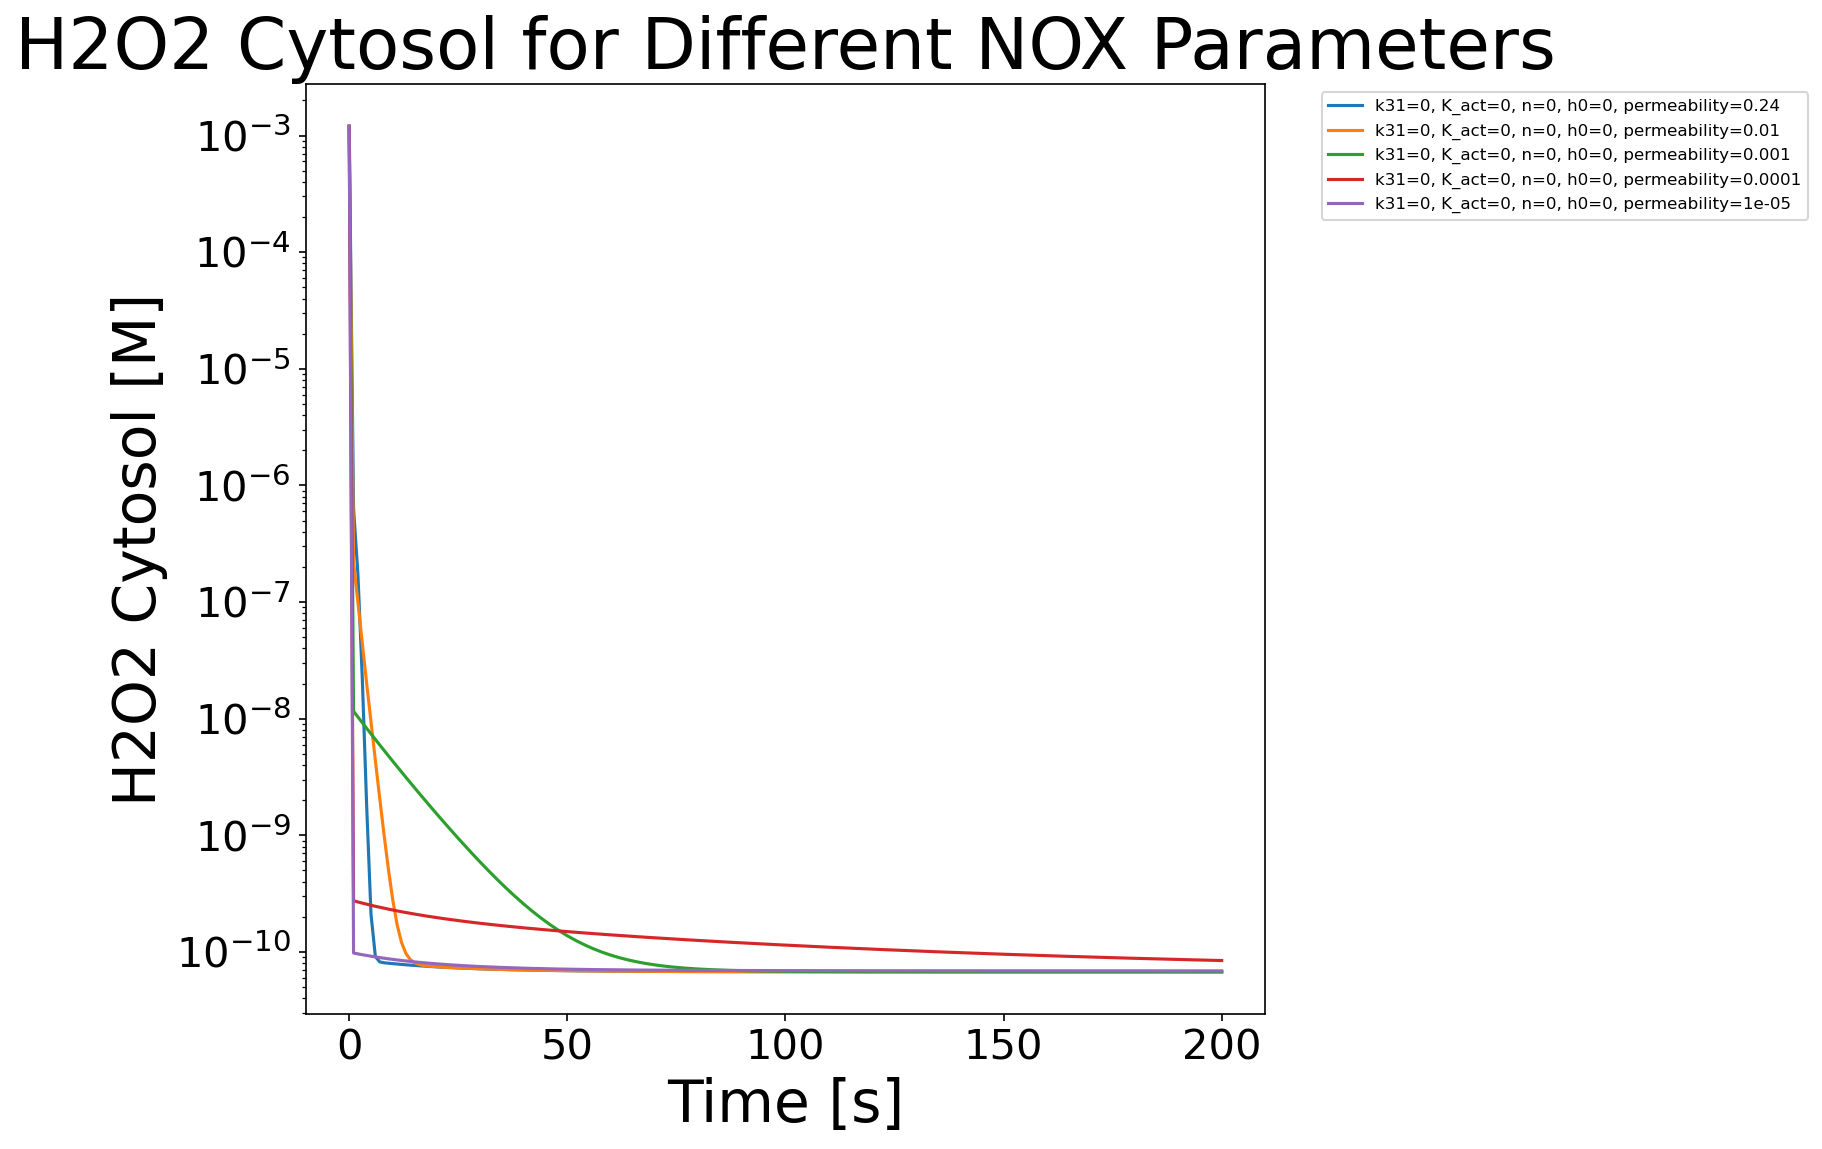

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parameter lists
k31_list = [0]#[8.87e-8]
K_act_list = [0]#[1e-9, 1e-8]
n_list = [0]#[1,3]
h_baseline_list = [0]#[4.5e-11, 1e-9]
permeability_coefficient_list = [24e-2, 1e-2, 1e-3, 1e-4, 1e-5]

# Store results for plotting
results = []
# Initial conditions

xnew = x0.copy()

xnew[1] = 0.0012  # Set initial H2O2cytosol concentration

# Define the parameterized model (copy your full ODEs here)
def model_noref_param(x, t, k, xnew, k31, K_act, n, h_baseline, permeability_coefficient_list):
    k = k.copy()
    k[31] = k31
    def nox_h2o2_rate(x, Vmax, K_act, n, h_baseline):
        h = max(x[1] - h_baseline, 0.0)
        f = (h**n) / (K_act**n + h**n) if h > 0 else 0.0
        return Vmax * f
    dxdt = np.zeros_like(x)
    k31_hill = nox_h2o2_rate(x, Vmax=k[31], K_act=K_act, n=n, h_baseline=h_baseline)
    k[0] = permeability_coefficient_list

    dxdt[0] = (k[0] * (x[1] - x[0]) * 10e-3 * 1.02e-5 * (1e9)) + k31_hill
    # --- Copy the rest of your ODEs from model_noref here ---

    dxdt[1] = (((k[0] * x[0] * 10e-3 * 5.3e-6) / (1.15e-12))
               - ((k[0] * x[1] * 10e-3 * 5.3e-6) / (1.15e-12))
               #- 2 * (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14)              # peroxisomal H2O2     
               - k[2] * x[2] * x[1]                             # GPx reduction of H2O2
               - k[5] * x[7] * x[1]                                   # catalase reaction
               - k[7] * x[9] * x[1]                                   # peroxiredoxin oxidation
               - k[8] * x[10] * x[1]                                  # overoxidized peroxiredoxin
               - k[13] * x[15] * x[1]                                 # Protein monothiol oxidation
               - k[17] * x[20] * x[1]                                 # Protein dithiol oxidation
               + k[1]                                                          # intracellular peroxide production
               + k[29] * x[25] * x[27])                                      # superoxide dismutase reduction and oxidation by superoxide

    dxdt[2] = (- k[2] * x[2] * x[1]
               + k[4] * x[4] * x[5])
    
    dxdt[3] = k[2] * x[2] * x[1] - k[3] * x[3] * x[5]
    dxdt[4] = k[3] * x[3] * x[5] - k[4] * x[4] * x[5]
    dxdt[5] = (- k[3] * x[3] * x[5]
               - k[4] * x[4] * x[5]
               - 2 * k[12] * x[5]
               - k[14] * x[16] * x[5]
               - k[16] * x[16] * x[5]
               + 2 * k[19] * x[6] * x[22]
               + k[23] 
               - k[25])
    dxdt[6] = (k[4] * x[4] * x[5] + k[12] * x[5] +
               k[16] * x[19] * x[5] - k[19] * x[6] * x[22] 
               - k[24] * x[6] / x0[6]
               - k[25] * x[6] / x0[6]
               )
    dxdt[7] = 0
    dxdt[8] = (k[22] * x[1] * 10e-3 * 2.98e-9) / (1.53e-14) - k[5] * x[7] * x[8]
    dxdt[9] = - k[7] * x[9] * x[1] + k[11] * x[12] * x[13]
    dxdt[10] = (k[7] * x[9] * x[1] - k[8] * x[10] * x[1] +
                k[9] * x[11] - k[10] * x[10])
    dxdt[11] = k[8] * x[10] * x[1] - k[9] * x[11]
    dxdt[12] = k[10] * x[10] - k[11] * x[12] * x[13]
    dxdt[13] = (- k[11] * x[12] * x[13] 
                - k[18] * x[21] * x[13] 
                + k[20] * x[14] * x[22] 
                - k[26] 
                + k[27])
    dxdt[14] = (k[11] * x[12] * x[13] + k[18] * x[21] * x[13] -
                k[20] * x[14] * x[22])

    dxdt[15] = (- k[13] * x[15] * (x[1])
                + k[15] * x[18] * (x[17]))

    dxdt[16] = k[13] * x[15] * x[1] - k[14] * x[16] * x[5]
    dxdt[17] = k[14] * x[16] * x[5] - k[15] * x[18] * x[17]
    dxdt[18] = k[16] * x[19] * x[5] - k[15] * x[18] * x[17]
    
    dxdt[19] = (k[15] * x[18] * x[17] 
                - k[16] * x[19] * x[5])
    
    dxdt[20] = - k[17] * x[20] * x[1] + k[18] * x[21] * x[13]
    dxdt[21] = k[17] * x[20] * x[1] - k[18] * x[21] * x[13]

    #NADPH
    dxdt[22] = (- k[19] * x[6] * x[22] 
                - k[20] * x[14] * x[22] 
                #- k[28] * x[22]                                         # nox generation of superoxide
                + k[21] * x[23] / (k[6] + x[23]))
    #NADP+
    dxdt[23] = (k[19] * x[6] * x[22] 
                + k[20] * x[14] * x[22] 
                #+ k[28] * x[22]                                         # nox generation of superoxide and nadp+
                - k[21] * x[23] / (k[6] + x[23]))

    dxdt[24] = (k[0] * (x[25] - x[24]) * 10e-3 * 1.02e-5 * (1e9)               # superoxide media
                + k[28] * x[22])
    
    dxdt[25] = (((k[0] * x[24] * 10e-3 * 1.02e-5) / (9.16e-13))                 # superoxide cytosol
               - ((k[0] * x[25] * 10e-3 * 1.02e-5) / (9.16e-13))
               - k[29] * x[25] * x[26]
               - k[29] * x[25] * x[27]
               + k[30])
    
    dxdt[26] = (k[29] * x[25] * x[27] 
                - k[29] * x[25] * x[26])

    dxdt[27] = (k[29] * x[25] * x[26] 
                - k[29] * x[25] * x[27])
    
    #dxdt[28] = 0#(((k[0] * x[29] * 10e-3 * 1.02e-5) / (9.16e-13))               # calcium cytosol
               #- ((k[0] * x[28] * 10e-3 * 1.02e-5) / (9.16e-13)))
               #+ (200e-6*(x[28]**2/(0.6e-6**2+x[28]**2))))
    
    #dxdt[29] = ((k[0] * 1e-3 * (x[28] - x[29]) * 10e-3 * 1.02e-5 * (1e9)) + k[32])               # calcium media
    
    return dxdt


# Time vector
t = np.linspace(0, 200, 201)

# Iterate and solve
for permeability_coefficient in permeability_coefficient_list:
    for k31 in k31_list:
        for K_act in K_act_list:
            for n_val in n_list:
                for h_baseline in h_baseline_list:
                    k_test = k.copy()
                    x0_test = xnew.copy()
                    # ODE function for solve_ivp (note: t and y order for solve_ivp)
                    ode_func = lambda t, y: model_noref_param(y, t, k_test, x0_test, k31, K_act, n_val, h_baseline, permeability_coefficient)
                    sol = solve_ivp(ode_func, (0, 200), x0_test, t_eval=t, method='Radau', atol=1e-10, rtol=1e-8)
                    results.append({
                        'k31': k31,
                        'K_act': K_act,
                        'n': n_val,
                        'h_baseline': h_baseline,
                        't': sol.t,
                        'H2O2_cytosol': sol.y[1],
                        'permeability_coefficient': permeability_coefficient
                    })
               
# Plotting
plt.figure(figsize=(12, 8))
for res in results:
    label = f"k31={res['k31']}, K_act={res['K_act']}, n={res['n']}, h0={res['h_baseline']}, permeability={res['permeability_coefficient']}"
    plt.plot(res['t'], res['H2O2_cytosol'], label=label)
plt.xlabel('Time [s]')
plt.ylabel('H2O2 Cytosol [M]')
plt.title('H2O2 Cytosol for Different NOX Parameters')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()